<a href="https://colab.research.google.com/github/JonatasYamaguti/4d-modulation-and-artificial-intelligence/blob/main/Redes_Neurais_IC_2_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Redes neurais para mitigação de erros em canal óptico AWGN

Esta versão deixa os experimentos separados por caso (`m = 4`, `m = 8` e `m = 16`) para facilitar a inspeção visual de cada etapa:

1. código esférico com ruído AWGN;
2. fibras de Hopf ruidosas;
3. modulações QAM ruidosas nos planos `(X1, X2)` e `(X3, X4)`;
4. regiões de decisão projetadas;
5. reconstrução do sinal a partir das modulações QAM;
6. curvas de SER e BER.

A SNR gráfica fica fixa em **15 dB**, como exemplo visual. As curvas de desempenho continuam avaliando vários valores de SNR.

O BER usa **mapeamento binário natural**, sem codificação Gray.


In [ ]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

try:
    import torch
    from torch import nn
    from torch.utils.data import TensorDataset, DataLoader
    TORCH_AVAILABLE = True
except ModuleNotFoundError:
    TORCH_AVAILABLE = False
    torch = None
    nn = object
    TensorDataset = None
    DataLoader = None
    print("PyTorch não foi encontrado neste kernel. As células de CNN serão ignoradas.")


RNG_SEED = 42
rng = np.random.default_rng(RNG_SEED)

SNR_VISUAL_DB = 15
SNR_CURVE_DB = np.arange(0, 25, 2)
N_PHASE = 8
GLOBAL_PHASES = 2*np.pi*np.arange(N_PHASE)/N_PHASE

RESULTS_DIR = Path("resultados_casos_separados")
RESULTS_DIR.mkdir(exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 10,
})


## Tabelas e parametrizações usadas

As amplitudes `ex`, `ey` e a diferença de fase `phi` vêm diretamente das tabelas do trabalho e são usadas para gerar os campos ópticos, os parâmetros de Stokes e as fibras de Hopf ruidosas:

`Ex = ex * exp(j*varphi)`

`Ey = ey * exp(j*(varphi + phi))`

onde `varphi` assume os 8 estados de fase global da modulação 8PSK.

Para a QAM 4D do caso `m = 8`, foi mantida a parametrização que você validou no código original, usando `theta_vals`, `phi_vals` e os 8 valores de `varphi`.

Para o caso `m = 16`, a QAM 4D agora segue a mesma lógica angular validada no `m = 8`: `theta = atan2(S2, S1)` e `phi = atan2(-S3, sqrt(S1^2 + S2^2))`, calculados a partir das coordenadas cartesianas da Tabela 10.


In [ ]:
SPHERICAL_CODES = {
    4: {
        "name": "4 pontos ótimos",
        "stokes": np.array([
            [ 0.5774,  0.5774,  0.5774],
            [ 0.5774, -0.5774, -0.5774],
            [-0.5774,  0.5774, -0.5774],
            [-0.5774, -0.5774,  0.5774],
        ], dtype=float),
        "ex": np.array([0.8881, 0.8881, 0.4597, 0.4597], dtype=float),
        "ey": np.array([0.4597, 0.4597, 0.8881, 0.8881], dtype=float),
        "phase_deg": np.array([-135.0, 45.0, 135.0, -45.0], dtype=float),
        "decision_radius_min": 0.0,
    },
    8: {
        "name": "8 pontos ótimos",
        "stokes": np.array([
            [ 0.6078,  0.6078, -0.5111],
            [-0.6078,  0.6078, -0.5111],
            [ 0.6078, -0.6078, -0.5111],
            [-0.6078, -0.6078, -0.5111],
            [ 0.8595,  0.0000,  0.5111],
            [-0.8595,  0.0000,  0.5111],
            [ 0.0000,  0.8595,  0.5111],
            [ 0.0000, -0.8595,  0.5111],
        ], dtype=float),
        "ex": np.array([0.8966, 0.4428, 0.8966, 0.4428, 0.9642, 0.2649, 0.7071, 0.7071], dtype=float),
        "ey": np.array([0.4428, 0.8966, 0.4428, 0.8966, 0.2649, 0.9642, 0.7071, 0.7071], dtype=float),
        "phase_deg": np.array([40.06, 40.06, 139.94, 139.94, -90.0, -90.0, -30.73, -149.27], dtype=float),
        # Construção QAM validada no experimento original.
        # Ela usa coordenadas angulares próprias para a constelação 4D,
        # em vez de projetar diretamente ex, ey e phase_deg no plano QAM.
        "qam_theta_vals": np.array([0.7853, 2.3561, -0.7853, -2.3561, 0.0, 3.1415, 1.5707, -1.5707], dtype=float),
        "qam_phi_vals": np.array([0.5364, 0.5364, 0.5364, 0.5364, -0.5364, -0.5364, -0.5364, -0.5364], dtype=float),
        # Para os limiares 2D, remove apenas o centro (0,0), que aparece como
        # projeção de alguns símbolos 4D. Os gráficos de QAM ruidosa continuam
        # mostrando todos os símbolos transmitidos.
        "decision_radius_min": 1e-3,
        "decision_center_mode": "literal_unique",
    },
    16: {
        "name": "16 pontos ótimos",
        "stokes": np.array([
            [ 0.3529,  0.7499, -0.5596],
            [-0.3910, -0.5093, -0.7666],
            [ 0.6234,  0.0565,  0.7799],
            [-0.8731,  0.1507,  0.4637],
            [ 0.2464, -0.8105,  0.5313],
            [-0.2874, -0.2701,  0.9189],
            [-0.4980,  0.8623, -0.0917],
            [-0.9249,  0.0311, -0.3790],
            [ 0.5242, -0.1725, -0.8339],
            [ 0.9385,  0.3291, -0.1044],
            [ 0.1946, -0.9301, -0.3114],
            [-0.6495, -0.7462,  0.1458],
            [ 0.4047,  0.8695,  0.2832],
            [ 0.8594, -0.5109,  0.0197],
            [-0.2083,  0.5699,  0.7949],
            [-0.3119,  0.3307, -0.8907],
        ], dtype=float),
        "ex": np.array([0.8225, 0.5518, 0.9009, 0.2519, 0.7894, 0.5969, 0.5010, 0.1938,
                        0.8730, 0.9845, 0.7729, 0.4186, 0.8381, 0.9642, 0.6292, 0.5866], dtype=float),
        "ey": np.array([0.5688, 0.8340, 0.4339, 0.9677, 0.6138, 0.8023, 0.8654, 0.9810,
                        0.4877, 0.1754, 0.6346, 0.9082, 0.5455, 0.2651, 0.7772, 0.8099], dtype=float),
        "phase_deg": np.array([36.73, 123.61, -85.85, -71.99, -146.75, -106.38, 6.08, -94.74,
                               101.69, 17.60, 161.49, -168.94, -18.04, -177.78, -54.37, 69.94], dtype=float),
        "qam_from_stokes_angles": True,
        "decision_radius_min": 0.0,
        "decision_center_mode": "literal_unique",
    },
}

for m, cfg in SPHERICAL_CODES.items():
    print(f"m={m}: {cfg['name']}")
    print(f"  símbolos 4D nPol-8PSK: {m*N_PHASE}")
    print(f"  bits/símbolo, mapeamento natural: {int(np.log2(m*N_PHASE))}")


m=4: 4 pontos ótimos
  símbolos 4D nPol-8PSK: 32
  bits/símbolo, mapeamento natural: 5
m=8: 8 pontos ótimos
  símbolos 4D nPol-8PSK: 64
  bits/símbolo, mapeamento natural: 6
m=16: 16 pontos ótimos
  símbolos 4D nPol-8PSK: 128
  bits/símbolo, mapeamento natural: 7


## Funções físicas e métricas

O ruído AWGN é aplicado nas quatro dimensões reais da constelação QAM 4D com energia média unitária por símbolo.

Para visualizar o código esférico com ruído, o ruído também é aplicado aos campos ópticos complexos `Ex` e `Ey`, e depois os parâmetros de Stokes normalizados são reconstruídos.


In [ ]:
def normalize_rows(x):
    x = np.asarray(x, dtype=float)
    return x / np.linalg.norm(x, axis=1, keepdims=True)


def build_constellation(m):
    cfg = SPHERICAL_CODES[m]
    constellation = []
    metadata = []

    uses_qam_angles = "qam_theta_vals" in cfg or cfg.get("qam_from_stokes_angles", False)

    if uses_qam_angles:
        if "qam_theta_vals" in cfg:
            theta_vals = cfg["qam_theta_vals"]
            phi_vals = cfg["qam_phi_vals"]
        else:
            stokes_norm = normalize_rows(cfg["stokes"])
            theta_vals = np.arctan2(stokes_norm[:, 1], stokes_norm[:, 0])
            phi_vals = np.arctan2(
                -stokes_norm[:, 2],
                np.hypot(stokes_norm[:, 0], stokes_norm[:, 1]),
            )

        for base_index, (theta, phi) in enumerate(zip(theta_vals, phi_vals)):
            for phase_index, varphi in enumerate(GLOBAL_PHASES):
                x1 = np.round(np.cos(theta/2) * np.cos(varphi + phi/2), 4)
                x2 = np.round(np.cos(theta/2) * np.sin(varphi + phi/2), 4)
                x3 = np.round(np.sin(theta/2) * np.cos(varphi - phi/2), 4)
                x4 = np.round(np.sin(theta/2) * np.sin(varphi - phi/2), 4)
                constellation.append([x1, x2, x3, x4])
                metadata.append((base_index, phase_index))
    else:
        ex = cfg["ex"]
        ey = cfg["ey"]
        rel_phase = np.deg2rad(cfg["phase_deg"])
        for base_index in range(m):
            for phase_index, varphi in enumerate(GLOBAL_PHASES):
                z_x = ex[base_index] * np.exp(1j*varphi)
                z_y = ey[base_index] * np.exp(1j*(varphi + rel_phase[base_index]))
                constellation.append([z_x.real, z_x.imag, z_y.real, z_y.imag])
                metadata.append((base_index, phase_index))

    constellation = np.array(constellation, dtype=float)
    if not uses_qam_angles:
        constellation = normalize_rows(constellation)

    return constellation, np.array(metadata, dtype=int)


def awgn_real_4d(x, snr_db, rng):
    snr_linear = 10**(snr_db/10)
    sigma = np.sqrt(1/(2*snr_linear))
    return x + rng.normal(0.0, sigma, size=x.shape)


def awgn_complex(x, snr_db, rng):
    snr_linear = 10**(snr_db/10)
    sigma = np.sqrt(1/(2*snr_linear))
    return x + sigma*(rng.normal(size=x.shape) + 1j*rng.normal(size=x.shape))


def generate_balanced_qam_dataset(m, snr_db, n_per_symbol, rng):
    constellation, metadata = build_constellation(m)
    labels = np.repeat(np.arange(len(constellation)), n_per_symbol)
    clean = np.repeat(constellation, n_per_symbol, axis=0)
    noisy = awgn_real_4d(clean, snr_db, rng)
    perm = rng.permutation(len(labels))
    return noisy[perm], labels[perm], constellation, metadata


def optical_fields_from_table(m):
    cfg = SPHERICAL_CODES[m]
    ex = cfg["ex"]
    ey = cfg["ey"]
    rel_phase = np.deg2rad(cfg["phase_deg"])
    e_x = ex.astype(complex)
    e_y = ey*np.exp(1j*rel_phase)
    return e_x, e_y


def stokes_from_fields(e_x, e_y):
    s0 = np.abs(e_x)**2 + np.abs(e_y)**2
    s1 = np.abs(e_x)**2 - np.abs(e_y)**2
    s2 = 2*np.real(e_x*np.conj(e_y))
    s3 = -2*np.imag(e_x*np.conj(e_y))
    return np.column_stack([s1/s0, s2/s0, s3/s0])


def generate_noisy_stokes(m, snr_db, n_per_base, rng):
    e_x_base, e_y_base = optical_fields_from_table(m)
    labels = np.repeat(np.arange(m), n_per_base)
    e_x = np.repeat(e_x_base, n_per_base)
    e_y = np.repeat(e_y_base, n_per_base)
    e_x_noisy = awgn_complex(e_x, snr_db, rng)
    e_y_noisy = awgn_complex(e_y, snr_db, rng)
    return stokes_from_fields(e_x_noisy, e_y_noisy), labels


def hopfmap(a, b, c, n=600):
    phi_hopf = np.linspace(0, 2*np.pi, n)
    theta_hopf = np.arctan2(b, -a) - phi_hopf
    alpha = np.sqrt(np.maximum((1 + c)/2, 0))
    beta = np.sqrt(np.maximum((1 - c)/2, 0))
    x = beta*np.cos(phi_hopf)
    y = beta*np.sin(phi_hopf)
    w = alpha*np.cos(theta_hopf)
    z = alpha*np.sin(theta_hopf)
    r = np.arccos(np.clip(w, -1.0, 1.0))/np.pi
    den = np.sqrt(np.maximum(1 - w**2, 1e-12))
    return r/den*x, r/den*y, r/den*z


def nearest_neighbor_predict(x, constellation, batch_size=50000):
    predictions = []
    for start in range(0, len(x), batch_size):
        xb = x[start:start+batch_size]
        dist2 = np.sum((xb[:, None, :] - constellation[None, :, :])**2, axis=2)
        predictions.append(np.argmin(dist2, axis=1))
    return np.concatenate(predictions)


def int_to_bits(value, width):
    return np.array([(value >> shift) & 1 for shift in range(width - 1, -1, -1)], dtype=int)


def natural_bit_table(m):
    num_symbols = m*N_PHASE
    width = int(np.log2(num_symbols))
    return np.array([int_to_bits(symbol, width) for symbol in range(num_symbols)], dtype=int)


def error_rates(y_true, y_pred, bit_table):
    ser = np.mean(y_true != y_pred)
    ber = np.mean(bit_table[y_true] != bit_table[y_pred])
    return ser, ber


## Funções de visualização

As regiões de decisão são desenhadas com os centros projetados da constelação QAM usada na transmissão. Para `m = 8`, a QAM é gerada pela construção angular validada no seu código original:

`theta_vals = [0.7853, 2.3561, -0.7853, -2.3561, 0.0, 3.1415, 1.5707, -1.5707]`

`phi_vals = [0.5364, 0.5364, 0.5364, 0.5364, -0.5364, -0.5364, -0.5364, -0.5364]`

Nos limiares 2D, o centro `(0,0)` é removido porque ele aparece apenas como projeção de alguns símbolos 4D. A QAM ruidosa continua mostrando todos os símbolos transmitidos.


In [ ]:
def plot_reference_sphere(ax):
    theta = np.linspace(0, 2*np.pi, 80)
    phi = np.linspace(0, np.pi, 40)
    theta, phi = np.meshgrid(theta, phi)
    x = np.sin(phi)*np.cos(theta)
    y = np.sin(phi)*np.sin(theta)
    z = np.cos(phi)
    ax.plot_surface(x, y, z, color="white", alpha=0.08, linewidth=0)
    ax.plot_wireframe(x, y, z, color="black", alpha=0.06, linewidth=0.4)


def plot_spherical_code_with_noise(m, snr_db=SNR_VISUAL_DB, n_per_base=250, save=True):
    stokes_noisy, labels = generate_noisy_stokes(m, snr_db, n_per_base, rng)
    stokes_ideal = normalize_rows(SPHERICAL_CODES[m]["stokes"])

    fig = plt.figure(figsize=(8, 7))
    ax = fig.add_subplot(111, projection="3d")
    plot_reference_sphere(ax)
    ax.scatter(stokes_noisy[:,0], stokes_noisy[:,1], stokes_noisy[:,2], s=5, alpha=0.25, label=f"AWGN {snr_db} dB")
    ax.scatter(stokes_ideal[:,0], stokes_ideal[:,1], stokes_ideal[:,2], c="red", s=80, marker="x", label="Pontos ideais")
    ax.set_xlabel("S1")
    ax.set_ylabel("S2")
    ax.set_zlabel("S3")
    ax.set_title(f"Código esférico com ruído - m={m}, SNR={snr_db} dB")
    ax.legend()
    if save:
        path = RESULTS_DIR / f"codigo_esferico_ruidoso_m{m}.png"
        fig.savefig(path, bbox_inches="tight")
        print(f"Figura salva em: {path}")
    return fig, ax


def plot_noisy_hopf_fibers(m, snr_db=SNR_VISUAL_DB, n_per_base=30, max_fibers=120, save=True):
    stokes_noisy, _ = generate_noisy_stokes(m, snr_db, n_per_base, rng)
    if len(stokes_noisy) > max_fibers:
        idx = rng.choice(len(stokes_noisy), size=max_fibers, replace=False)
        stokes_noisy = stokes_noisy[idx]

    fig = plt.figure(figsize=(8, 7))
    ax = fig.add_subplot(111, projection="3d")
    for s1, s2, s3 in stokes_noisy:
        fx, fy, fz = hopfmap(s1, s2, s3, n=500)
        ax.plot3D(fx, fy, fz, linewidth=0.45, alpha=0.50)
    ax.set_xlabel("S1")
    ax.set_ylabel("S2")
    ax.set_zlabel("S3")
    ax.set_title(f"Fibras de Hopf ruidosas - m={m}, SNR={snr_db} dB")
    if save:
        path = RESULTS_DIR / f"fibras_hopf_ruidosas_m{m}.png"
        fig.savefig(path, bbox_inches="tight")
        print(f"Figura salva em: {path}")
    return fig, ax


def plot_noisy_qam(m, axes=(0, 1), snr_db=SNR_VISUAL_DB, n_per_symbol=120, save=True):
    x_noisy, y, constellation, _ = generate_balanced_qam_dataset(m, snr_db, n_per_symbol, rng)
    fig, ax = plt.subplots(figsize=(7, 7))
    ax.scatter(x_noisy[:, axes[0]], x_noisy[:, axes[1]], s=3, alpha=0.18, label=f"Amostras AWGN {snr_db} dB")
    ax.scatter(constellation[:, axes[0]], constellation[:, axes[1]], c="red", marker="x", s=42, label="Centros 4D projetados")
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel(f"X{axes[0]+1}")
    ax.set_ylabel(f"X{axes[1]+1}")
    ax.set_title(f"QAM ruidosa - m={m}, plano X{axes[0]+1}X{axes[1]+1}")
    ax.legend()
    if save:
        path = RESULTS_DIR / f"qam_ruidosa_m{m}_X{axes[0]+1}X{axes[1]+1}.png"
        fig.savefig(path, bbox_inches="tight")
        print(f"Figura salva em: {path}")
    return fig, ax


def plot_noisy_qam_all_symbols(m, axes=(0, 1), snr_db=SNR_VISUAL_DB, n_per_symbol=80, save=True):
    x_noisy, labels, constellation, _ = generate_balanced_qam_dataset(m, snr_db, n_per_symbol, rng)
    cmap = make_symbol_cmap(len(constellation))

    fig, ax = plt.subplots(figsize=(8, 7))
    sc = ax.scatter(
        x_noisy[:, axes[0]], x_noisy[:, axes[1]],
        c=labels,
        cmap=cmap,
        s=4,
        alpha=0.32,
        linewidths=0,
        label=f"Símbolos transmitidos com AWGN {snr_db} dB",
    )
    ax.scatter(
        constellation[:, axes[0]], constellation[:, axes[1]],
        c=np.arange(len(constellation)),
        cmap=cmap,
        s=42,
        marker="x",
        linewidths=1.1,
        label="Centros ideais projetados",
    )
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel(f"X{axes[0]+1}")
    ax.set_ylabel(f"X{axes[1]+1}")
    ax.set_title(f"QAM transmitida com ruído - m={m}, plano X{axes[0]+1}X{axes[1]+1}")
    cbar = fig.colorbar(sc, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label("Índice do símbolo 4D")
    ax.legend(loc="upper right")
    if save:
        path = RESULTS_DIR / f"qam_todos_simbolos_ruido_m{m}_X{axes[0]+1}X{axes[1]+1}.png"
        fig.savefig(path, bbox_inches="tight")
        print(f"Figura salva em: {path}")
    return fig, ax


def unique_projected_centers(points_2d, tol=1e-5, radius_min=0.0):
    radius = np.linalg.norm(points_2d, axis=1)
    keep = radius >= radius_min
    pts = points_2d[keep]
    keys = np.round(pts/tol).astype(int)
    _, unique_idx = np.unique(keys, axis=0, return_index=True)
    centers = pts[np.sort(unique_idx)]
    return centers


def ring_8psk_centers(points_2d, tol=1e-4, radius_min=0.0):
    radius = np.linalg.norm(points_2d, axis=1)
    radius = radius[radius >= radius_min]
    unique_radii = np.unique(np.round(radius/tol).astype(int))*tol
    centers = []
    for r_value in unique_radii:
        for phase in GLOBAL_PHASES:
            centers.append([r_value*np.cos(phase), r_value*np.sin(phase)])
    return np.array(centers, dtype=float)


def make_symbol_cmap(n):
    colors = plt.cm.hsv(np.linspace(0, 1, n, endpoint=False))
    colors[:, 3] = 1.0
    return ListedColormap(colors)


def decision_centers_for_projection(m, axes=(0, 1), radius_min=None, center_mode=None):
    constellation, _ = build_constellation(m)
    if radius_min is None:
        radius_min = SPHERICAL_CODES[m]["decision_radius_min"]
    if center_mode is None:
        center_mode = SPHERICAL_CODES[m].get("decision_center_mode", "literal_unique")

    if center_mode == "ring_8psk":
        centers = ring_8psk_centers(constellation[:, axes], radius_min=radius_min)
    elif center_mode == "literal_unique":
        centers = unique_projected_centers(constellation[:, axes], radius_min=radius_min)
    else:
        raise ValueError("center_mode deve ser 'ring_8psk' ou 'literal_unique'")

    return centers, center_mode


def plot_decision_regions(m, axes=(0, 1), resolution=450, radius_min=None, center_mode=None, save=True):
    centers, center_mode = decision_centers_for_projection(
        m, axes=axes, radius_min=radius_min, center_mode=center_mode
    )
    n_centers = len(centers)
    print(f"m={m}, plano X{axes[0]+1}X{axes[1]+1}: {n_centers} centros usados nas regiões ({center_mode}).")

    margin = 0.18
    xmin, ymin = centers.min(axis=0) - margin
    xmax, ymax = centers.max(axis=0) + margin
    xx, yy = np.meshgrid(np.linspace(xmin, xmax, resolution), np.linspace(ymin, ymax, resolution))
    grid = np.column_stack([xx.ravel(), yy.ravel()])
    dist2 = np.sum((grid[:, None, :] - centers[None, :, :])**2, axis=2)
    labels = np.argmin(dist2, axis=1).reshape(xx.shape)
    cmap = make_symbol_cmap(n_centers)

    fig, ax = plt.subplots(figsize=(8, 7))
    ax.contourf(xx, yy, labels, levels=np.arange(n_centers + 1) - 0.5, cmap=cmap, alpha=0.22)
    ax.contour(xx, yy, labels, levels=np.arange(n_centers + 1) - 0.5, colors="black", linewidths=0.25, alpha=0.55)
    ax.scatter(centers[:,0], centers[:,1], c=np.arange(n_centers), cmap=cmap, s=34, edgecolors="black", linewidths=0.45)

    for i, (xv, yv) in enumerate(centers):
        ax.text(xv, yv, str(i), ha="center", va="center", fontsize=6)

    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel(f"X{axes[0]+1}")
    ax.set_ylabel(f"X{axes[1]+1}")
    ax.set_title(f"Regiões de decisão QAM - m={m}, plano X{axes[0]+1}X{axes[1]+1}")
    if save:
        suffix = center_mode
        path = RESULTS_DIR / f"regioes_decisao_m{m}_X{axes[0]+1}X{axes[1]+1}_{suffix}.png"
        fig.savefig(path, bbox_inches="tight")
        print(f"Figura salva em: {path}")
    return fig, ax, centers


def plot_decision_regions_with_noise(
    m,
    axes=(0, 1),
    snr_db=SNR_VISUAL_DB,
    n_per_symbol=60,
    resolution=450,
    radius_min=None,
    center_mode=None,
    save=True,
):
    centers, center_mode = decision_centers_for_projection(
        m, axes=axes, radius_min=radius_min, center_mode=center_mode
    )
    n_centers = len(centers)
    x_noisy, labels, constellation, _ = generate_balanced_qam_dataset(m, snr_db, n_per_symbol, rng)

    margin = 0.18
    xmin = min(centers[:, 0].min(), x_noisy[:, axes[0]].min()) - margin
    xmax = max(centers[:, 0].max(), x_noisy[:, axes[0]].max()) + margin
    ymin = min(centers[:, 1].min(), x_noisy[:, axes[1]].min()) - margin
    ymax = max(centers[:, 1].max(), x_noisy[:, axes[1]].max()) + margin
    xx, yy = np.meshgrid(np.linspace(xmin, xmax, resolution), np.linspace(ymin, ymax, resolution))
    grid = np.column_stack([xx.ravel(), yy.ravel()])
    dist2 = np.sum((grid[:, None, :] - centers[None, :, :])**2, axis=2)
    region_labels = np.argmin(dist2, axis=1).reshape(xx.shape)
    cmap_regions = make_symbol_cmap(n_centers)
    cmap_symbols = make_symbol_cmap(len(constellation))

    fig, ax = plt.subplots(figsize=(8, 7))
    ax.contourf(xx, yy, region_labels, levels=np.arange(n_centers + 1) - 0.5, cmap=cmap_regions, alpha=0.16)
    ax.contour(xx, yy, region_labels, levels=np.arange(n_centers + 1) - 0.5, colors="black", linewidths=0.25, alpha=0.55)
    ax.scatter(
        x_noisy[:, axes[0]], x_noisy[:, axes[1]],
        c=labels,
        cmap=cmap_symbols,
        s=4,
        alpha=0.28,
        linewidths=0,
        label=f"Todos os símbolos com AWGN {snr_db} dB",
    )
    ax.scatter(centers[:, 0], centers[:, 1], c="black", marker="+", s=38, linewidths=0.9, label="Centros de decisão")
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel(f"X{axes[0]+1}")
    ax.set_ylabel(f"X{axes[1]+1}")
    ax.set_title(
        f"QAM com ruído e limiares - m={m}, plano X{axes[0]+1}X{axes[1]+1}"
    )
    ax.legend(loc="upper right")
    if save:
        path = RESULTS_DIR / f"qam_ruido_limiares_m{m}_X{axes[0]+1}X{axes[1]+1}_{center_mode}.png"
        fig.savefig(path, bbox_inches="tight")
        print(f"Figura salva em: {path}")
    return fig, ax, centers


def diagnose_qam_projection(m):
    constellation, _ = build_constellation(m)
    print(f"Diagnóstico das projeções QAM para m={m}")
    for axes in [(0, 1), (2, 3)]:
        literal = unique_projected_centers(constellation[:, axes], radius_min=0.0)
        decision_centers, mode = decision_centers_for_projection(m, axes=axes)
        radii = np.unique(np.round(np.linalg.norm(constellation[:, axes], axis=1), 4))
        print(f"  Plano X{axes[0]+1}X{axes[1]+1}:")
        print(f"    raios únicos: {radii}")
        print(f"    centros projetados incluindo (0,0): {len(literal)}")
        print(f"    centros usados nos limiares ({mode}): {len(decision_centers)}")


def plot_qam_reconstruction(m, snr_db=SNR_VISUAL_DB, n_per_symbol=150, save=True):
    x_noisy, y_true, constellation, _ = generate_balanced_qam_dataset(m, snr_db, n_per_symbol, rng)
    y_pred = nearest_neighbor_predict(x_noisy, constellation)
    x_rec = constellation[y_pred]
    errors = y_pred != y_true
    ser = errors.mean()

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    for ax, pair in zip(axes, [(0, 1), (2, 3)]):
        ax.scatter(x_rec[~errors, pair[0]], x_rec[~errors, pair[1]], s=8, alpha=0.55, label="Reconstruído correto")
        ax.scatter(x_rec[errors, pair[0]], x_rec[errors, pair[1]], s=14, c="red", alpha=0.70, label="Reconstruído com erro")
        ax.set_aspect("equal", adjustable="box")
        ax.set_xlabel(f"X{pair[0]+1}")
        ax.set_ylabel(f"X{pair[1]+1}")
        ax.set_title(f"Reconstrução QAM X{pair[0]+1}X{pair[1]+1}")
        ax.legend()
    fig.suptitle(f"Reconstrução por vizinho próximo 4D - m={m}, SNR={snr_db} dB, SER={ser:.3e}")
    fig.tight_layout()
    if save:
        path = RESULTS_DIR / f"reconstrucao_qam_m{m}.png"
        fig.savefig(path, bbox_inches="tight")
        print(f"Figura salva em: {path}")
    return fig, axes, y_true, y_pred, x_rec


def plot_reconstructed_sphere(m, y_pred, save=True):
    _, metadata = build_constellation(m)
    base_pred = metadata[y_pred, 0]
    stokes_ideal = normalize_rows(SPHERICAL_CODES[m]["stokes"])
    stokes_rec = stokes_ideal[base_pred]

    fig = plt.figure(figsize=(8, 7))
    ax = fig.add_subplot(111, projection="3d")
    plot_reference_sphere(ax)
    ax.scatter(stokes_rec[:,0], stokes_rec[:,1], stokes_rec[:,2], s=10, alpha=0.25, label="Reconstruído")
    ax.scatter(stokes_ideal[:,0], stokes_ideal[:,1], stokes_ideal[:,2], c="red", marker="x", s=80, label="Pontos ideais")
    ax.set_xlabel("S1")
    ax.set_ylabel("S2")
    ax.set_zlabel("S3")
    ax.set_title(f"Esfera de Poincaré reconstruída - m={m}")
    ax.legend()
    if save:
        path = RESULTS_DIR / f"esfera_reconstruida_m{m}.png"
        fig.savefig(path, bbox_inches="tight")
        print(f"Figura salva em: {path}")
    return fig, ax


## CNN e curvas de desempenho

A CNN permanece como detector a ser avaliado. Como a entrada tem apenas quatro atributos, ela deve ser comparada com o detector geométrico de vizinho mais próximo 4D.

Nesta versão, o treino padrão da CNN usa SNR fixa de 15 dB. Depois, a rede treinada é avaliada em vários valores de SNR para formar as curvas SER/BER.


In [ ]:
if TORCH_AVAILABLE:
    class CNNDetector(nn.Module):
        def __init__(self, num_classes):
            super().__init__()
            self.net = nn.Sequential(
                nn.Conv2d(1, 16, kernel_size=2),
                nn.ReLU(),
                nn.Flatten(),
                nn.Linear(16, 64),
                nn.ReLU(),
                nn.Dropout(0.10),
                nn.Linear(64, num_classes),
            )

        def forward(self, x):
            return self.net(x)
else:
    CNNDetector = None


def to_cnn_tensor(x, device):
    x = x.reshape(-1, 1, 2, 2).astype(np.float32)
    return torch.tensor(x, dtype=torch.float32, device=device)


def train_cnn_detector(m, snr_db=SNR_VISUAL_DB, n_per_symbol=400, epochs=25, batch_size=256, lr=1e-3, seed=RNG_SEED, verbose=True):
    if not TORCH_AVAILABLE:
        print("CNN não treinada: PyTorch indisponível.")
        return None, None, None

    local_rng = np.random.default_rng(seed + m)
    torch.manual_seed(seed + m)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed + m)

    x, y, constellation, _ = generate_balanced_qam_dataset(m, snr_db, n_per_symbol, local_rng)
    idx = local_rng.permutation(len(y))
    val_size = int(0.2*len(y))
    val_idx = idx[:val_size]
    train_idx = idx[val_size:]

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    x_train = to_cnn_tensor(x[train_idx], device)
    y_train = torch.tensor(y[train_idx], dtype=torch.long, device=device)
    x_val = to_cnn_tensor(x[val_idx], device)
    y_val = torch.tensor(y[val_idx], dtype=torch.long, device=device)

    loader = DataLoader(TensorDataset(x_train, y_train), batch_size=batch_size, shuffle=True)
    model = CNNDetector(num_classes=len(constellation)).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {"epoch": [], "loss": [], "val_accuracy": []}

    for epoch in range(1, epochs + 1):
        model.train()
        loss_sum = 0.0
        for xb, yb in loader:
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()
            loss_sum += loss.item()*len(yb)

        model.eval()
        with torch.no_grad():
            pred = torch.argmax(model(x_val), dim=1)
            val_acc = (pred == y_val).float().mean().item()
        train_loss = loss_sum/len(train_idx)
        history["epoch"].append(epoch)
        history["loss"].append(train_loss)
        history["val_accuracy"].append(val_acc)
        if verbose:
            print(f"Época {epoch:02d}/{epochs} | loss={train_loss:.5f} | val_acc={val_acc:.4f}")

    return model, history, device


def predict_cnn(model, x, device, batch_size=8192):
    preds = []
    model.eval()
    with torch.no_grad():
        for start in range(0, len(x), batch_size):
            xb = to_cnn_tensor(x[start:start+batch_size], device)
            preds.append(torch.argmax(model(xb), dim=1).cpu().numpy())
    return np.concatenate(preds)


def evaluate_over_snr(m, model=None, device=None, n_per_symbol=800, seed=RNG_SEED + 1000):
    local_rng = np.random.default_rng(seed + m)
    bit_table = natural_bit_table(m)
    rows = []

    for snr_db in SNR_CURVE_DB:
        x_test, y_test, constellation, _ = generate_balanced_qam_dataset(m, snr_db, n_per_symbol, local_rng)
        y_ml = nearest_neighbor_predict(x_test, constellation)
        ser_ml, ber_ml = error_rates(y_test, y_ml, bit_table)

        ser_cnn = np.nan
        ber_cnn = np.nan
        if model is not None:
            y_cnn = predict_cnn(model, x_test, device)
            ser_cnn, ber_cnn = error_rates(y_test, y_cnn, bit_table)

        rows.append({
            "snr_db": float(snr_db),
            "ser_ml": float(ser_ml),
            "ber_ml": float(ber_ml),
            "ser_cnn": float(ser_cnn),
            "ber_cnn": float(ber_cnn),
        })
        print(f"SNR={snr_db:>4.1f} dB | ML SER={ser_ml:.3e}, BER={ber_ml:.3e} | CNN SER={ser_cnn:.3e}, BER={ber_cnn:.3e}")

    return rows


def plot_error_curves(results, m, save=True):
    snr = np.array([row["snr_db"] for row in results])
    ser_ml = np.array([row["ser_ml"] for row in results])
    ber_ml = np.array([row["ber_ml"] for row in results])
    ser_cnn = np.array([row["ser_cnn"] for row in results])
    ber_cnn = np.array([row["ber_cnn"] for row in results])
    floor = 1e-6

    fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True)
    axes[0].semilogy(snr, np.maximum(ser_ml, floor), "o-", label="Vizinho próximo 4D")
    if np.isfinite(ser_cnn).any():
        axes[0].semilogy(snr, np.maximum(ser_cnn, floor), "s-", label="CNN treinada em 15 dB")
    axes[0].set_title(f"SER x SNR - m={m}")
    axes[0].set_xlabel("SNR (dB)")
    axes[0].set_ylabel("SER")
    axes[0].legend()

    axes[1].semilogy(snr, np.maximum(ber_ml, floor), "o-", label="Vizinho próximo 4D")
    if np.isfinite(ber_cnn).any():
        axes[1].semilogy(snr, np.maximum(ber_cnn, floor), "s-", label="CNN treinada em 15 dB")
    axes[1].set_title(f"BER x SNR - m={m} - binário natural")
    axes[1].set_xlabel("SNR (dB)")
    axes[1].set_ylabel("BER")
    axes[1].legend()
    fig.tight_layout()

    if save:
        path = RESULTS_DIR / f"curvas_SER_BER_m{m}.png"
        fig.savefig(path, bbox_inches="tight")
        print(f"Figura salva em: {path}")
    return fig, axes


def classification_metrics(y_true, y_pred, num_classes, bit_table):
    y_true = np.asarray(y_true, dtype=int)
    y_pred = np.asarray(y_pred, dtype=int)

    accuracy = float(np.mean(y_true == y_pred))
    precision_values = []
    recall_values = []
    f1_values = []

    for class_index in range(num_classes):
        tp = np.sum((y_true == class_index) & (y_pred == class_index))
        fp = np.sum((y_true != class_index) & (y_pred == class_index))
        fn = np.sum((y_true == class_index) & (y_pred != class_index))

        precision = tp/(tp + fp) if (tp + fp) > 0 else 0.0
        recall = tp/(tp + fn) if (tp + fn) > 0 else 0.0
        f1 = 2*precision*recall/(precision + recall) if (precision + recall) > 0 else 0.0

        precision_values.append(precision)
        recall_values.append(recall)
        f1_values.append(f1)

    ser, ber = error_rates(y_true, y_pred, bit_table)
    return {
        "accuracy": accuracy,
        "precision": float(np.mean(precision_values)),
        "recall": float(np.mean(recall_values)),
        "f1_score": float(np.mean(f1_values)),
        "ser": float(ser),
        "ber": float(ber),
    }


def repeated_metric_analysis(
    m_values=(4, 8, 16),
    snr_db=SNR_VISUAL_DB,
    n_repeats=30,
    train_n_per_symbol=300,
    test_n_per_symbol=800,
    epochs=25,
    batch_size=256,
    include_ml_baseline=True,
    seed=RNG_SEED + 5000,
):
    rows = []

    for m in m_values:
        constellation, _ = build_constellation(m)
        num_classes = len(constellation)
        bit_table = natural_bit_table(m)

        for run_index in range(1, n_repeats + 1):
            run_seed = seed + 100000*m + run_index
            test_rng = np.random.default_rng(run_seed + 777)
            x_test, y_test, constellation, _ = generate_balanced_qam_dataset(
                m, snr_db, test_n_per_symbol, test_rng
            )

            if include_ml_baseline:
                y_ml = nearest_neighbor_predict(x_test, constellation)
                metrics_ml = classification_metrics(y_test, y_ml, num_classes, bit_table)
                rows.append({
                    "m": m,
                    "detector": "Vizinho próximo 4D",
                    "snr_db": float(snr_db),
                    "run": run_index,
                    **metrics_ml,
                })

            if TORCH_AVAILABLE:
                model, _, device = train_cnn_detector(
                    m=m,
                    snr_db=snr_db,
                    n_per_symbol=train_n_per_symbol,
                    epochs=epochs,
                    batch_size=batch_size,
                    seed=run_seed,
                    verbose=False,
                )
                y_cnn = predict_cnn(model, x_test, device)
                metrics_cnn = classification_metrics(y_test, y_cnn, num_classes, bit_table)
                rows.append({
                    "m": m,
                    "detector": "CNN",
                    "snr_db": float(snr_db),
                    "run": run_index,
                    **metrics_cnn,
                })

            print(f"m={m} | execução {run_index}/{n_repeats} concluída")

    if not TORCH_AVAILABLE:
        print("PyTorch indisponível: a tabela contém apenas o detector de vizinho próximo 4D.")

    return rows


def summarize_metric_rows(rows):
    metric_names = ["accuracy", "precision", "recall", "f1_score", "ser", "ber"]
    groups = {}

    for row in rows:
        key = (row["m"], row["detector"], row["snr_db"])
        groups.setdefault(key, []).append(row)

    summary = []
    for (m, detector, snr_db), group_rows in sorted(groups.items()):
        item = {
            "m": m,
            "detector": detector,
            "snr_db": snr_db,
            "n": len(group_rows),
        }
        for metric in metric_names:
            values = np.array([row[metric] for row in group_rows], dtype=float)
            mean = float(np.mean(values))
            std = float(np.std(values, ddof=1)) if len(values) > 1 else 0.0
            ci95 = float(1.96*std/np.sqrt(len(values))) if len(values) > 1 else 0.0
            item[f"{metric}_mean"] = mean
            item[f"{metric}_std"] = std
            item[f"{metric}_ci95"] = ci95
            item[f"{metric}_mean_std"] = f"{mean:.4f} ± {std:.4f}"
            item[f"{metric}_mean_ci95"] = f"{mean:.4f} ± {ci95:.4f}"
        summary.append(item)

    return summary


def print_metric_summary(summary):
    headers = ["m", "Detector", "SNR", "N", "Acurácia", "Precisão", "Recall", "F1-score", "SER", "BER"]
    print(" | ".join(headers))
    print("-" * 118)
    for row in summary:
        print(
            f"{row['m']} | {row['detector']} | {row['snr_db']:.1f} | {row['n']} | "
            f"{row['accuracy_mean_std']} | {row['precision_mean_std']} | "
            f"{row['recall_mean_std']} | {row['f1_score_mean_std']} | "
            f"{row['ser_mean_std']} | {row['ber_mean_std']}"
        )


def save_metric_tables(rows, summary, prefix="metricas_repetidas"):
    import csv

    raw_path = RESULTS_DIR / f"{prefix}_bruto.csv"
    summary_path = RESULTS_DIR / f"{prefix}_resumo.csv"

    if rows:
        with raw_path.open("w", newline="", encoding="utf-8") as f:
            writer = csv.DictWriter(f, fieldnames=list(rows[0].keys()))
            writer.writeheader()
            writer.writerows(rows)

    if summary:
        with summary_path.open("w", newline="", encoding="utf-8") as f:
            writer = csv.DictWriter(f, fieldnames=list(summary[0].keys()))
            writer.writeheader()
            writer.writerows(summary)

    print(f"Resultados brutos salvos em: {raw_path}")
    print(f"Resumo estatístico salvo em: {summary_path}")
    return raw_path, summary_path


# Caso separado: `m = 4`

Este bloco gera as visualizações e métricas do código esférico de 4 pontos ótimos.


Figura salva em: resultados_casos_separados/codigo_esferico_ruidoso_m4.png
Figura salva em: resultados_casos_separados/fibras_hopf_ruidosas_m4.png
Figura salva em: resultados_casos_separados/qam_ruidosa_m4_X1X2.png
Figura salva em: resultados_casos_separados/qam_ruidosa_m4_X3X4.png
m=4, plano X1X2: 16 centros usados nas regiões (literal_unique).
Figura salva em: resultados_casos_separados/regioes_decisao_m4_X1X2_literal_unique.png
m=4, plano X3X4: 16 centros usados nas regiões (literal_unique).
Figura salva em: resultados_casos_separados/regioes_decisao_m4_X3X4_literal_unique.png
Figura salva em: resultados_casos_separados/reconstrucao_qam_m4.png
Figura salva em: resultados_casos_separados/esfera_reconstruida_m4.png


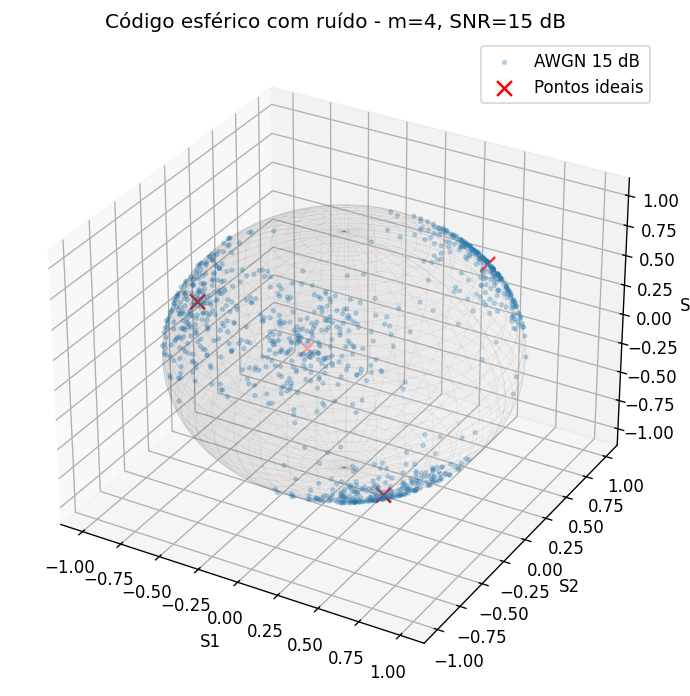

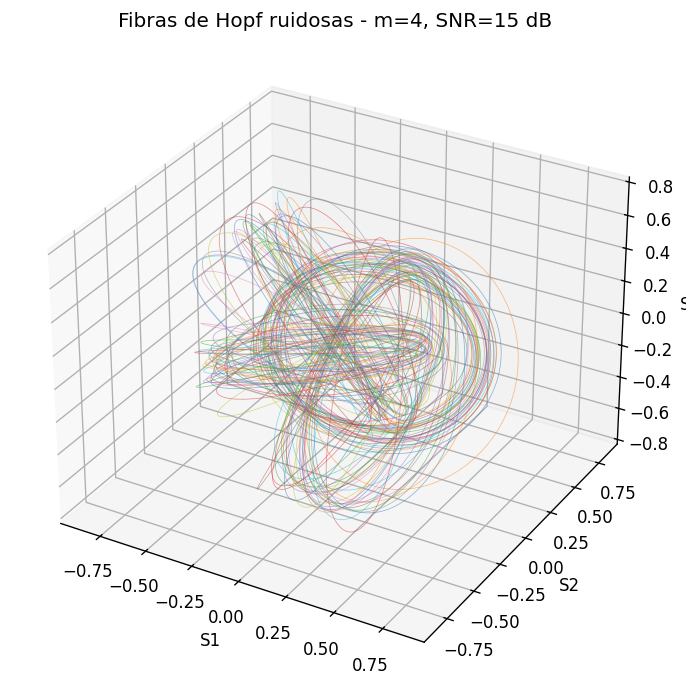

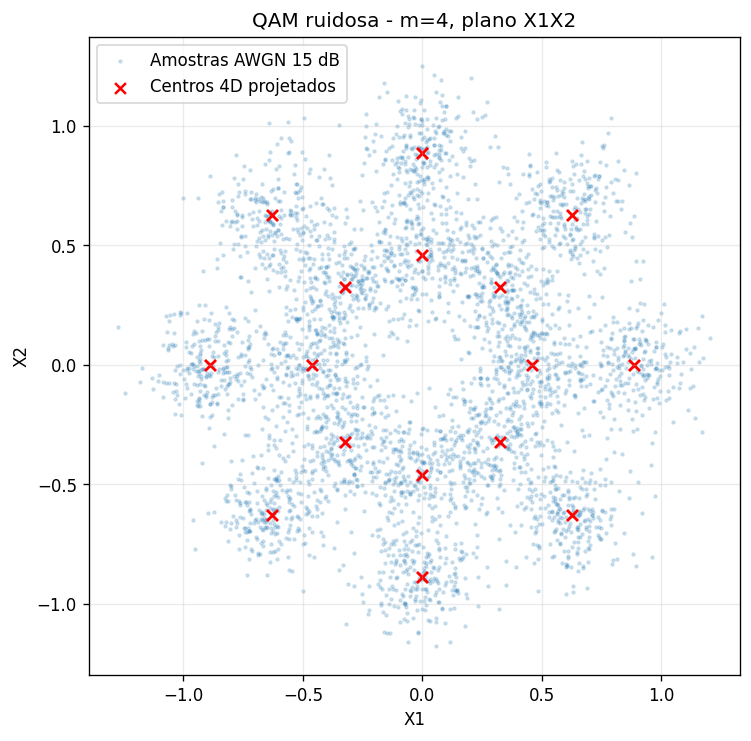

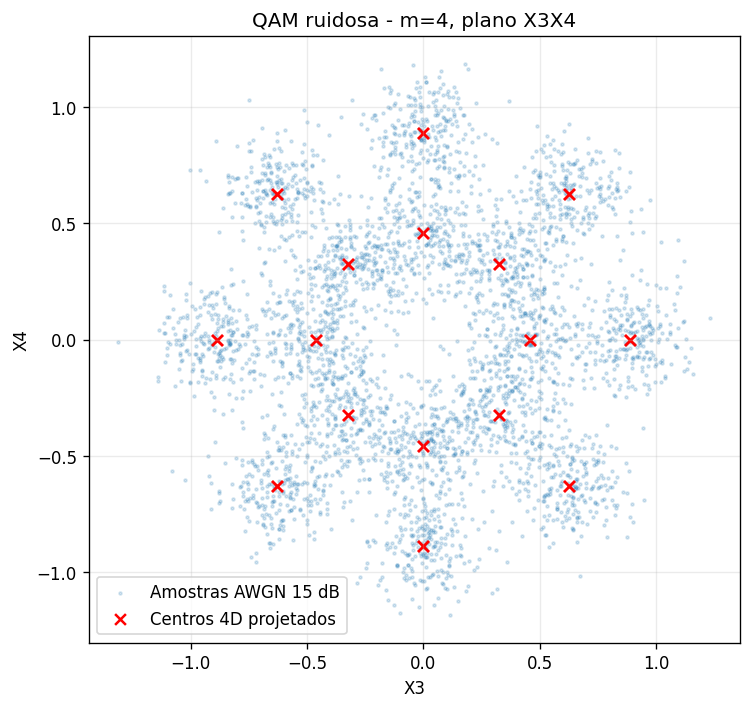

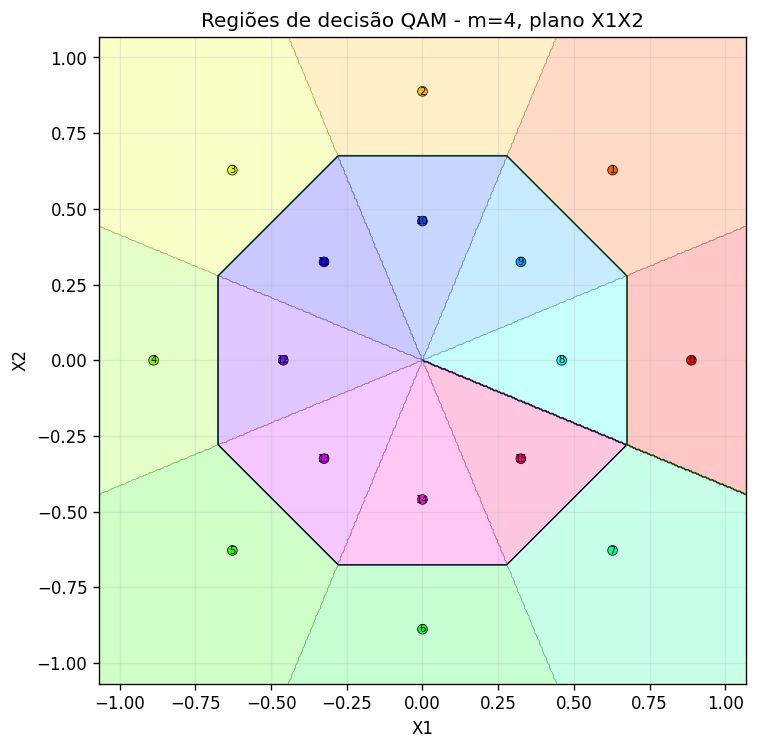

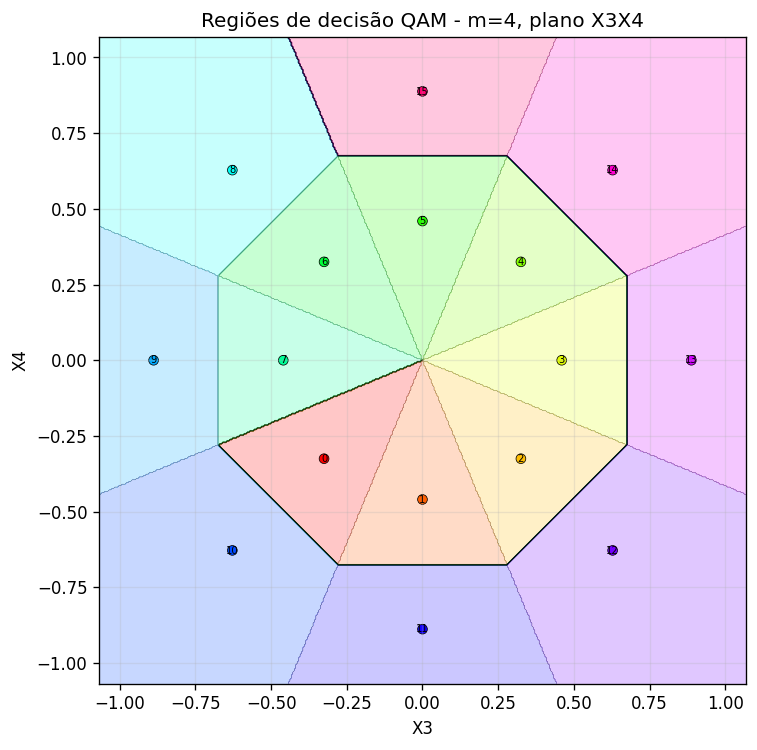

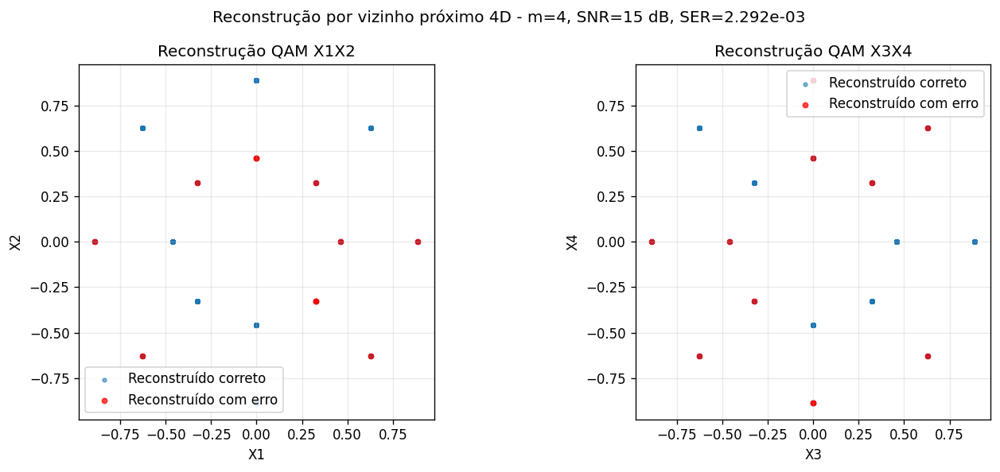

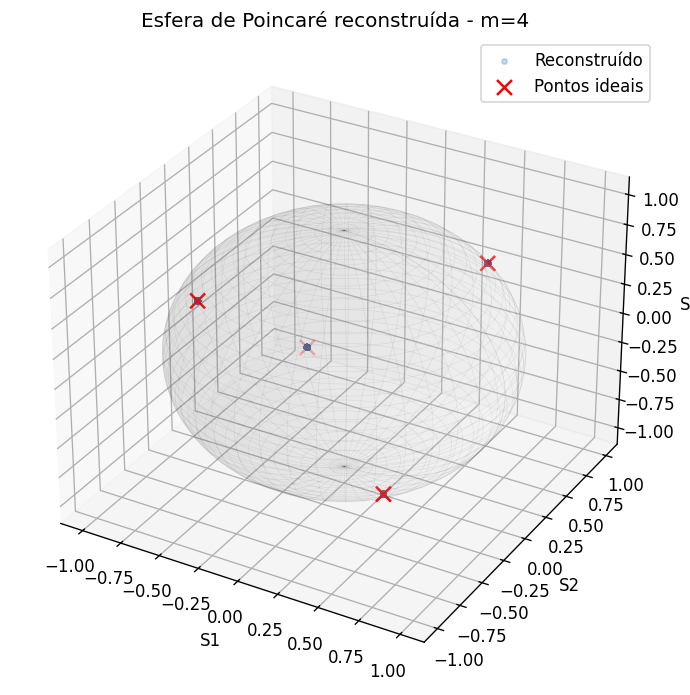

In [ ]:
m_case = 4

plot_spherical_code_with_noise(m_case, snr_db=SNR_VISUAL_DB)
plot_noisy_hopf_fibers(m_case, snr_db=SNR_VISUAL_DB)
plot_noisy_qam(m_case, axes=(0, 1), snr_db=SNR_VISUAL_DB)
plot_noisy_qam(m_case, axes=(2, 3), snr_db=SNR_VISUAL_DB)
plot_decision_regions(m_case, axes=(0, 1))
plot_decision_regions(m_case, axes=(2, 3))

fig_rec_m4, axes_rec_m4, y_true_m4, y_pred_m4, x_rec_m4 = plot_qam_reconstruction(m_case, snr_db=SNR_VISUAL_DB)
plot_reconstructed_sphere(m_case, y_pred_m4)
plt.show()


## CNN e curvas para `m = 4`

Use `RUN_CNN_M4 = True` para treinar a CNN. Se `torch` estiver indisponível, o notebook calcula apenas a referência por vizinho próximo 4D.


Época 01/25 | loss=3.38701 | val_acc=0.2918
Época 02/25 | loss=3.08824 | val_acc=0.3812
Época 03/25 | loss=2.52734 | val_acc=0.7215
Época 04/25 | loss=1.84498 | val_acc=0.9363
Época 05/25 | loss=1.21689 | val_acc=0.9723
Época 06/25 | loss=0.76560 | val_acc=0.9855
Época 07/25 | loss=0.48541 | val_acc=0.9914
Época 08/25 | loss=0.32733 | val_acc=0.9941
Época 09/25 | loss=0.23799 | val_acc=0.9953
Época 10/25 | loss=0.18063 | val_acc=0.9965
Época 11/25 | loss=0.14451 | val_acc=0.9969
Época 12/25 | loss=0.12155 | val_acc=0.9977
Época 13/25 | loss=0.10382 | val_acc=0.9973
Época 14/25 | loss=0.08930 | val_acc=0.9969
Época 15/25 | loss=0.07890 | val_acc=0.9980
Época 16/25 | loss=0.07232 | val_acc=0.9980
Época 17/25 | loss=0.06546 | val_acc=0.9977
Época 18/25 | loss=0.06026 | val_acc=0.9980
Época 19/25 | loss=0.05528 | val_acc=0.9977
Época 20/25 | loss=0.05062 | val_acc=0.9984
Época 21/25 | loss=0.04586 | val_acc=0.9973
Época 22/25 | loss=0.04442 | val_acc=0.9980
Época 23/25 | loss=0.04238 | val

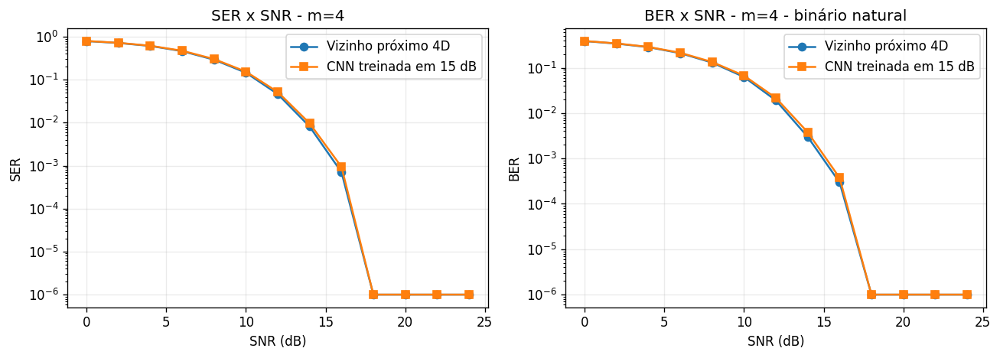

In [ ]:
RUN_CNN_M4 = True

model_m4 = device_m4 = None
if RUN_CNN_M4 and TORCH_AVAILABLE:
    model_m4, history_m4, device_m4 = train_cnn_detector(m=4, snr_db=SNR_VISUAL_DB, n_per_symbol=400, epochs=25)

results_m4 = evaluate_over_snr(m=4, model=model_m4, device=device_m4, n_per_symbol=800)
plot_error_curves(results_m4, m=4)
plt.show()


# Caso separado: `m = 8`

Este bloco gera as visualizações e métricas do código esférico de 8 pontos ótimos.

Antes dos gráficos, o notebook imprime um diagnóstico das projeções QAM. Com a construção angular validada para `m = 8`, cada plano possui 32 centros não nulos para os limiares de decisão. O ponto `(0,0)` aparece apenas como projeção de alguns símbolos 4D e é mantido nos gráficos com ruído, mas removido da malha de limiares 2D.


Diagnóstico das projeções QAM para m=8
  Plano X1X2:
    raios únicos: [0.     0.3827 0.7072 0.9239 1.    ]
    centros projetados incluindo (0,0): 33
    centros usados nos limiares (literal_unique): 32
  Plano X3X4:
    raios únicos: [0.     0.3826 0.3827 0.7071 0.9238 1.    ]
    centros projetados incluindo (0,0): 33
    centros usados nos limiares (literal_unique): 32
Figura salva em: resultados_casos_separados/codigo_esferico_ruidoso_m8.png
Figura salva em: resultados_casos_separados/fibras_hopf_ruidosas_m8.png
Figura salva em: resultados_casos_separados/qam_ruidosa_m8_X1X2.png
Figura salva em: resultados_casos_separados/qam_ruidosa_m8_X3X4.png
Figura salva em: resultados_casos_separados/qam_todos_simbolos_ruido_m8_X1X2.png
Figura salva em: resultados_casos_separados/qam_todos_simbolos_ruido_m8_X3X4.png
m=8, plano X1X2: 32 centros usados nas regiões (literal_unique).
Figura salva em: resultados_casos_separados/regioes_decisao_m8_X1X2_literal_unique.png
m=8, plano X3X4: 32 centros

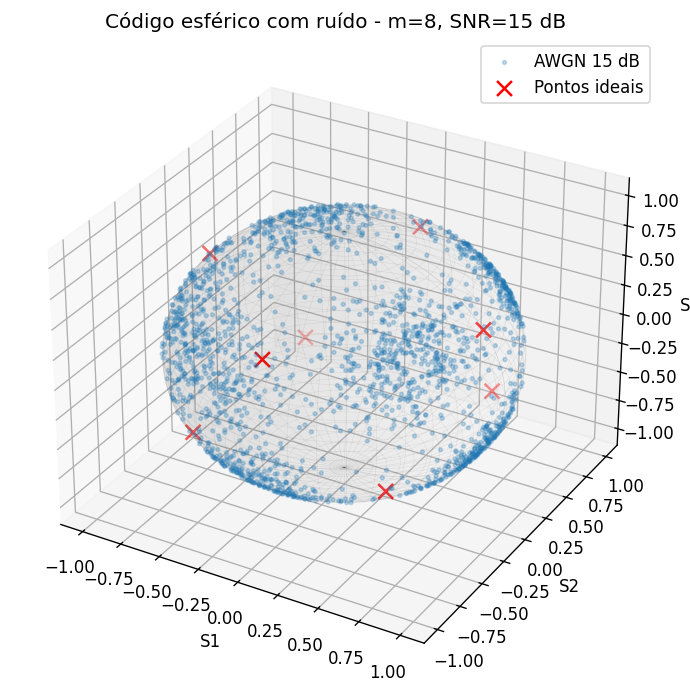

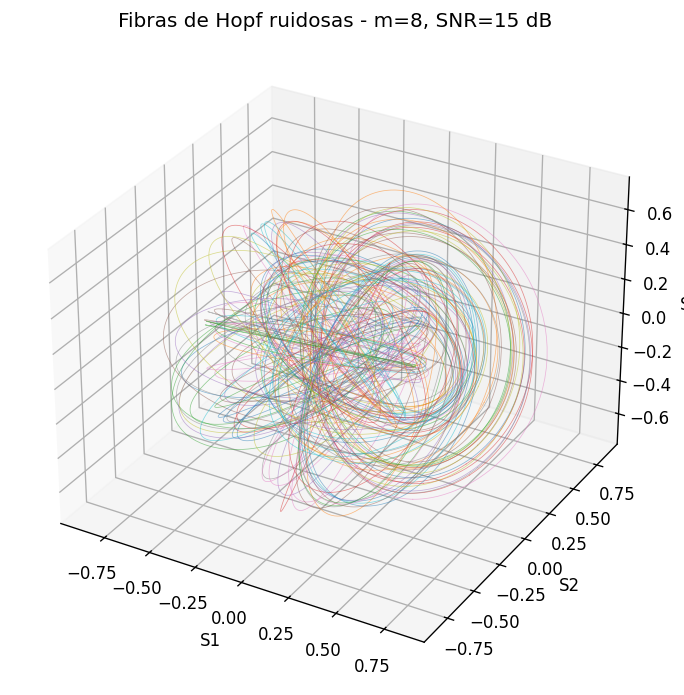

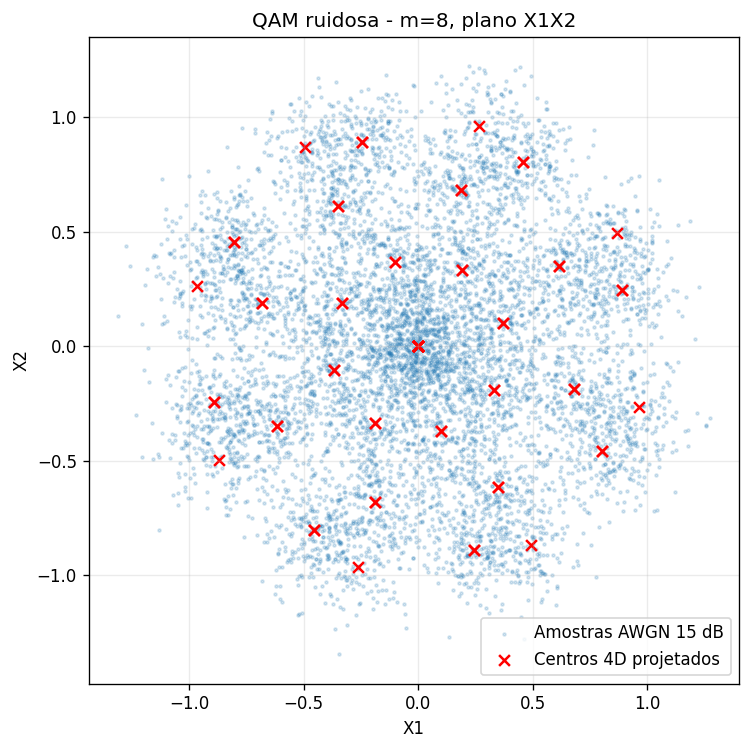

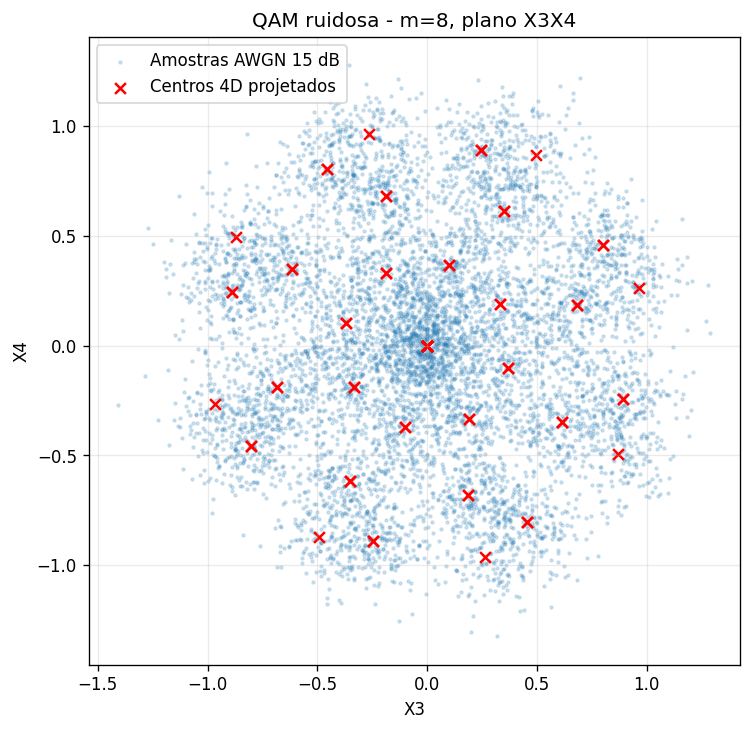

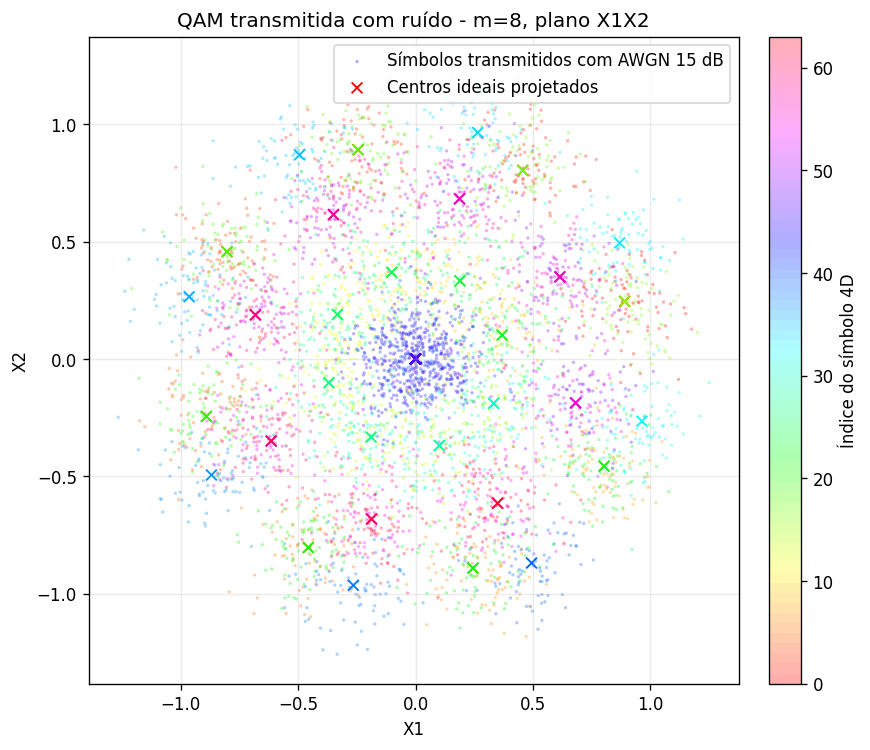

...

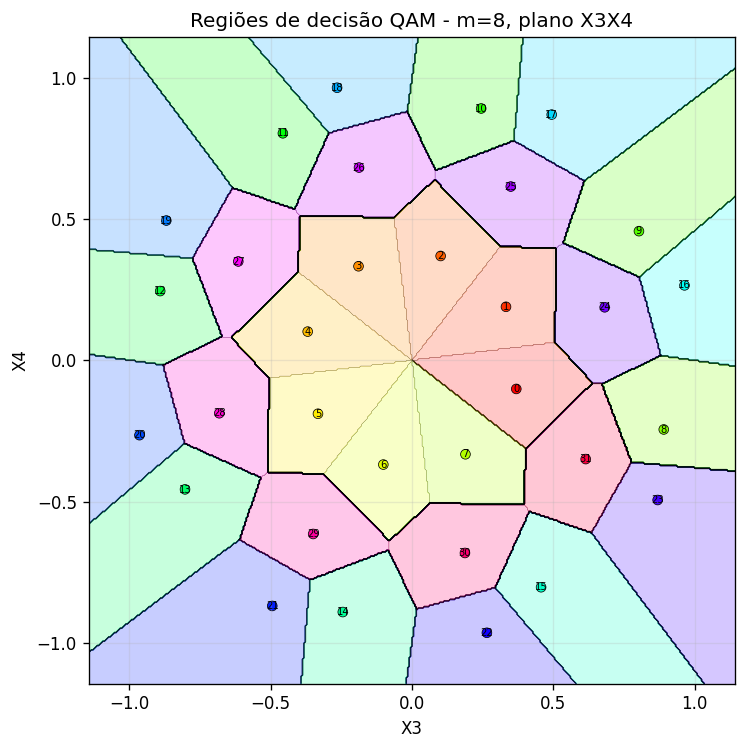

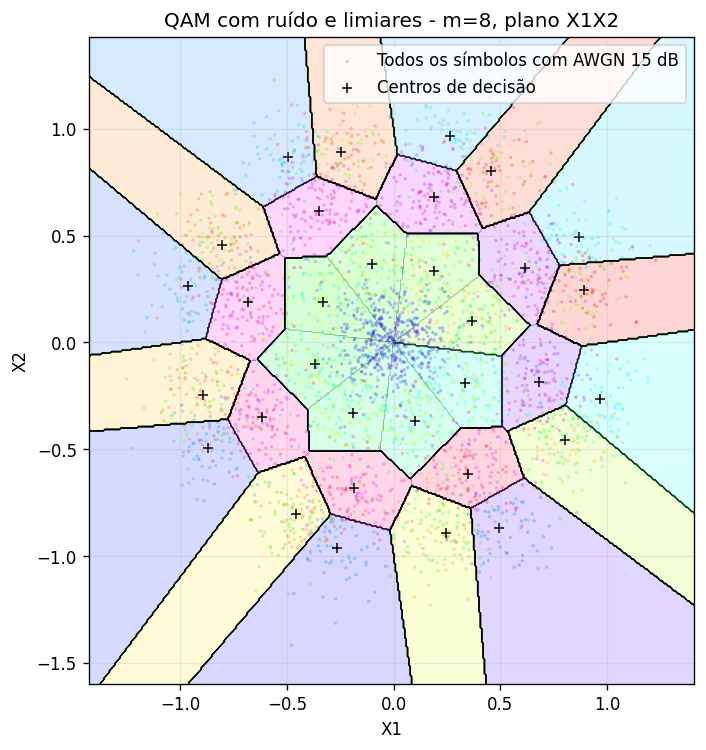

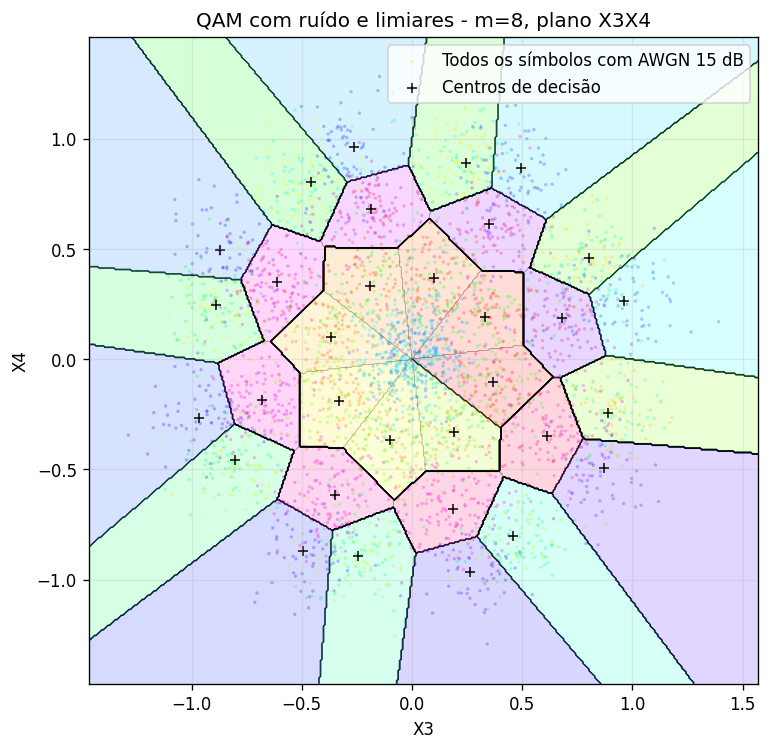

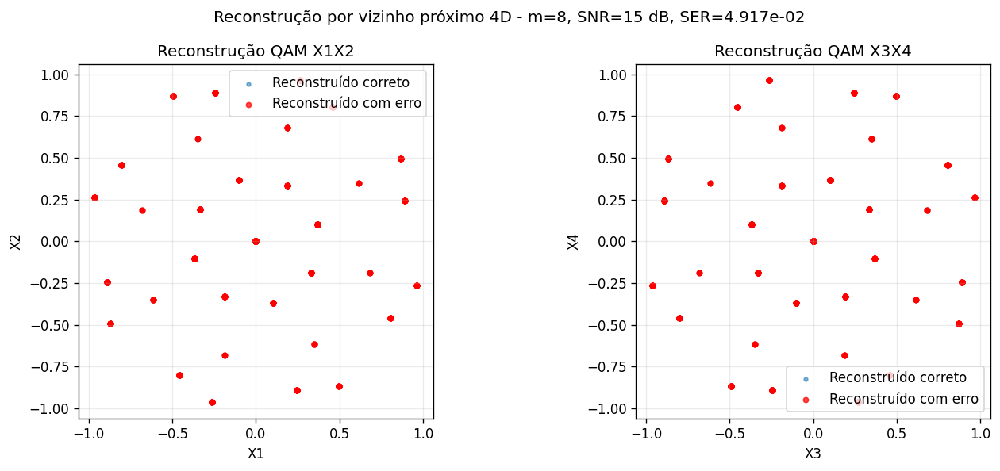

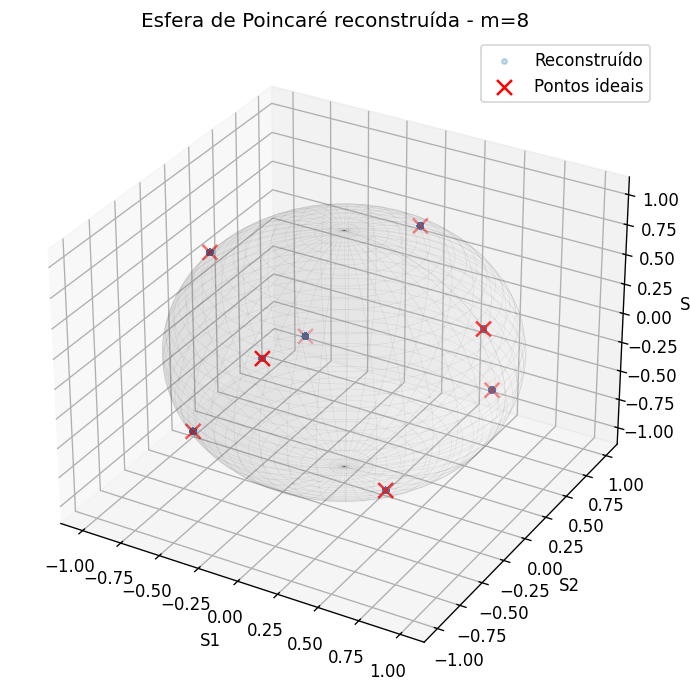

In [ ]:
m_case = 8

diagnose_qam_projection(m_case)

plot_spherical_code_with_noise(m_case, snr_db=SNR_VISUAL_DB)
plot_noisy_hopf_fibers(m_case, snr_db=SNR_VISUAL_DB)

plot_noisy_qam(m_case, axes=(0, 1), snr_db=SNR_VISUAL_DB)
plot_noisy_qam(m_case, axes=(2, 3), snr_db=SNR_VISUAL_DB)

plot_noisy_qam_all_symbols(m_case, axes=(0, 1), snr_db=SNR_VISUAL_DB)
plot_noisy_qam_all_symbols(m_case, axes=(2, 3), snr_db=SNR_VISUAL_DB)

plot_decision_regions(m_case, axes=(0, 1))
plot_decision_regions(m_case, axes=(2, 3))

plot_decision_regions_with_noise(m_case, axes=(0, 1), snr_db=SNR_VISUAL_DB)
plot_decision_regions_with_noise(m_case, axes=(2, 3), snr_db=SNR_VISUAL_DB)

fig_rec_m8, axes_rec_m8, y_true_m8, y_pred_m8, x_rec_m8 = plot_qam_reconstruction(m_case, snr_db=SNR_VISUAL_DB)
plot_reconstructed_sphere(m_case, y_pred_m8)
plt.show()


## CNN e curvas para `m = 8`

Use `RUN_CNN_M8 = True` para treinar a CNN. Para testes rápidos, reduza `n_per_symbol` ou `epochs`.


Época 01/25 | loss=4.00623 | val_acc=0.1961
Época 02/25 | loss=3.07094 | val_acc=0.6488
Época 03/25 | loss=1.81857 | val_acc=0.9117
Época 04/25 | loss=1.04870 | val_acc=0.9340
Época 05/25 | loss=0.67594 | val_acc=0.9393
Época 06/25 | loss=0.49320 | val_acc=0.9398
Época 07/25 | loss=0.39945 | val_acc=0.9441
Época 08/25 | loss=0.34295 | val_acc=0.9443
Época 09/25 | loss=0.30196 | val_acc=0.9434
Época 10/25 | loss=0.27951 | val_acc=0.9473
Época 11/25 | loss=0.25925 | val_acc=0.9473
Época 12/25 | loss=0.24614 | val_acc=0.9473
Época 13/25 | loss=0.23193 | val_acc=0.9486
Época 14/25 | loss=0.22482 | val_acc=0.9486
Época 15/25 | loss=0.21775 | val_acc=0.9500
Época 16/25 | loss=0.21091 | val_acc=0.9492
Época 17/25 | loss=0.20669 | val_acc=0.9506
Época 18/25 | loss=0.20341 | val_acc=0.9512
Época 19/25 | loss=0.19833 | val_acc=0.9498
Época 20/25 | loss=0.19382 | val_acc=0.9508
Época 21/25 | loss=0.19031 | val_acc=0.9484
Época 22/25 | loss=0.18724 | val_acc=0.9486
Época 23/25 | loss=0.18710 | val

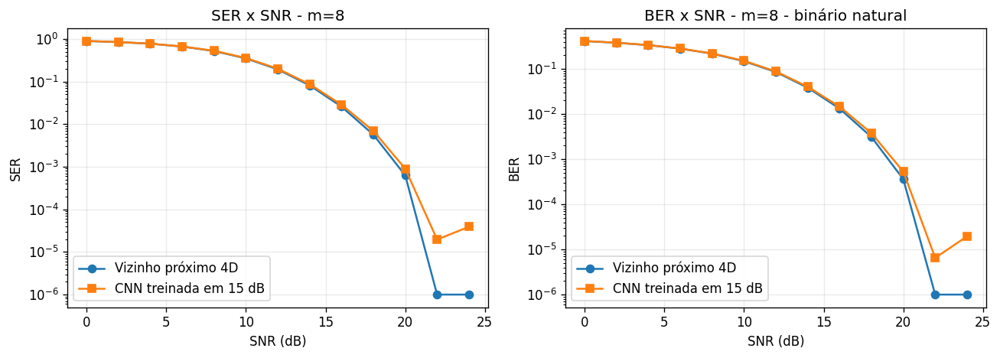

In [ ]:
RUN_CNN_M8 = True

model_m8 = device_m8 = None
if RUN_CNN_M8 and TORCH_AVAILABLE:
    model_m8, history_m8, device_m8 = train_cnn_detector(m=8, snr_db=SNR_VISUAL_DB, n_per_symbol=400, epochs=25)

results_m8 = evaluate_over_snr(m=8, model=model_m8, device=device_m8, n_per_symbol=800)
plot_error_curves(results_m8, m=8)
plt.show()


# Caso separado: `m = 16`

Este bloco implementa o código esférico de 16 pontos ótimos usando a Tabela 10. Para evitar o mesmo problema observado no `m = 8`, a geração da QAM 4D usa a lógica angular:

`theta = atan2(S2, S1)`

`phi = atan2(-S3, sqrt(S1^2 + S2^2))`

Depois, as 8 fases globais completam a modulação nPol-8PSK.


Diagnóstico das projeções QAM para m=16
  Plano X1X2:
    raios únicos: [0.0168 0.0169 0.0853 0.0854 0.3683 0.3684 0.3961 0.3962 0.4144 0.4422
 0.4999 0.5    0.573  0.7761 0.8034 0.8432 0.8443 0.8444 0.9642 0.9643
 0.9858 0.9859 0.9874 0.9989 0.999 ]
    centros projetados incluindo (0,0): 128
    centros usados nos limiares (literal_unique): 128
  Plano X3X4:
    raios únicos: [0.0451 0.0452 0.1582 0.1583 0.1678 0.265  0.5358 0.5359 0.5376 0.5954
 0.5955 0.6306 0.8196 0.866  0.8661 0.8969 0.897  0.9101 0.9181 0.9182
 0.9297 0.9963 0.9964 0.9998 0.9999]
    centros projetados incluindo (0,0): 128
    centros usados nos limiares (literal_unique): 128
Figura salva em: resultados_casos_separados/codigo_esferico_ruidoso_m16.png
Figura salva em: resultados_casos_separados/fibras_hopf_ruidosas_m16.png
Figura salva em: resultados_casos_separados/qam_ruidosa_m16_X1X2.png
Figura salva em: resultados_casos_separados/qam_ruidosa_m16_X3X4.png
Figura salva em: resultados_casos_separados/qam_todos_s

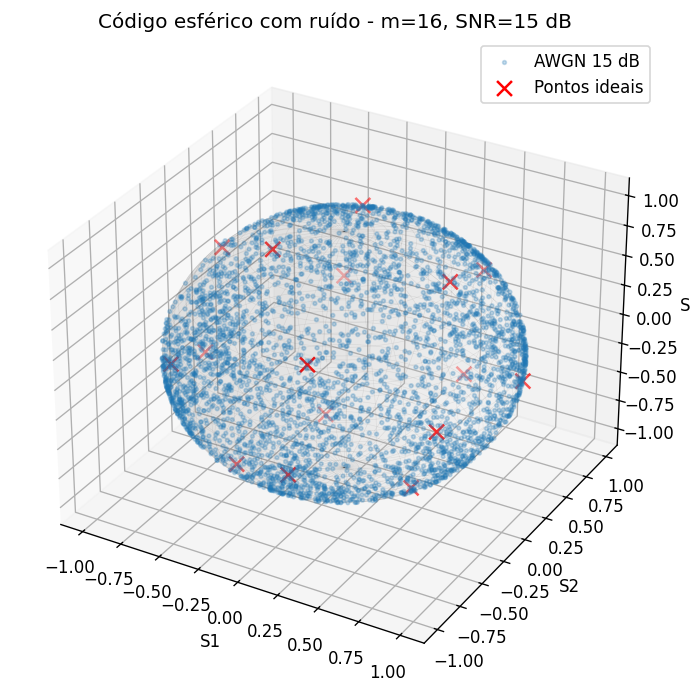

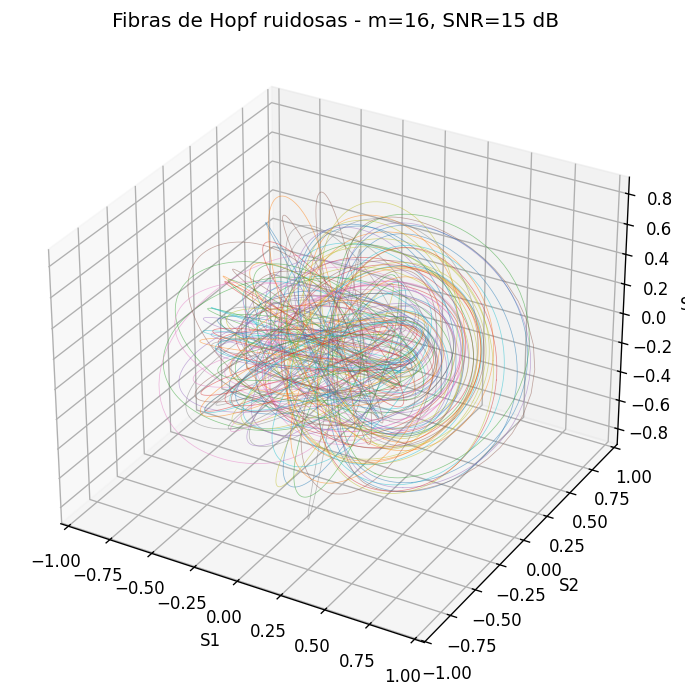

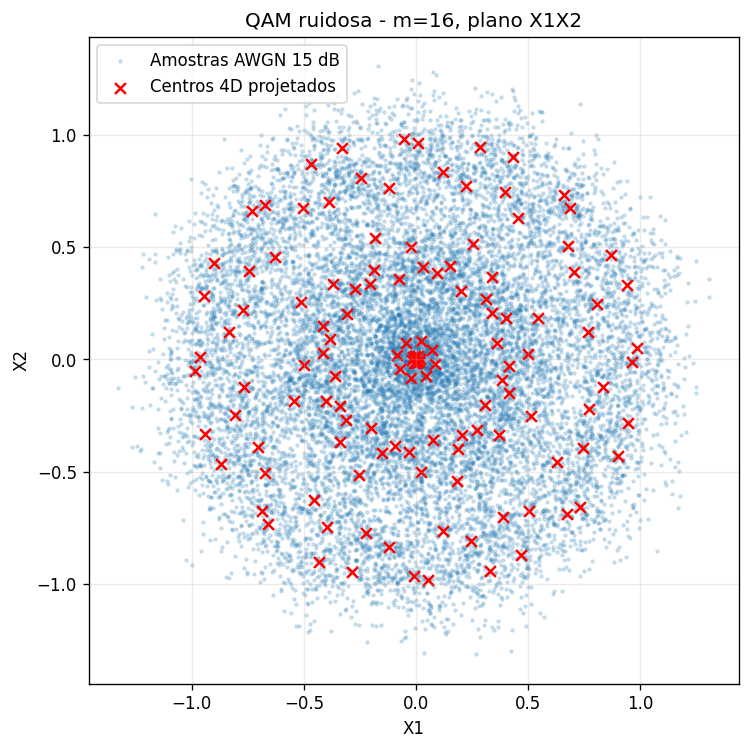

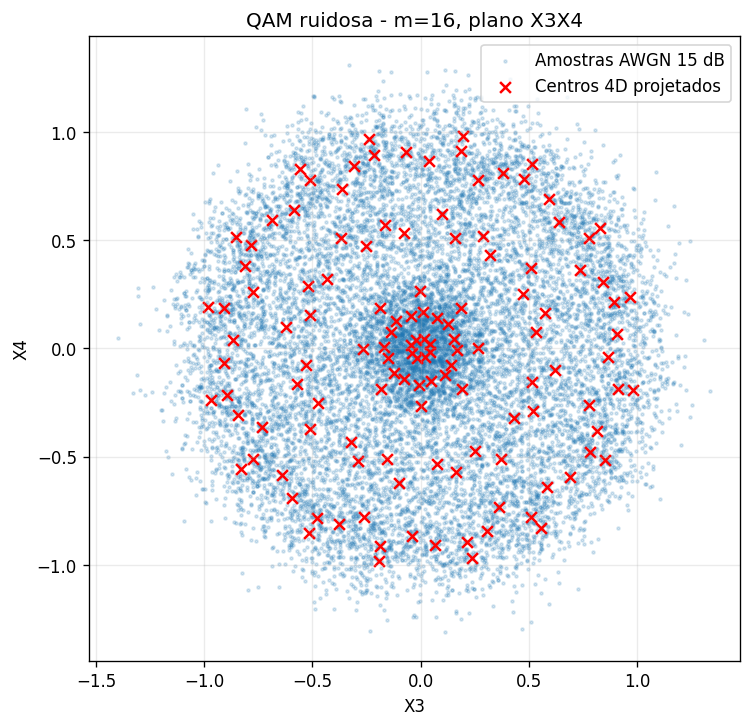

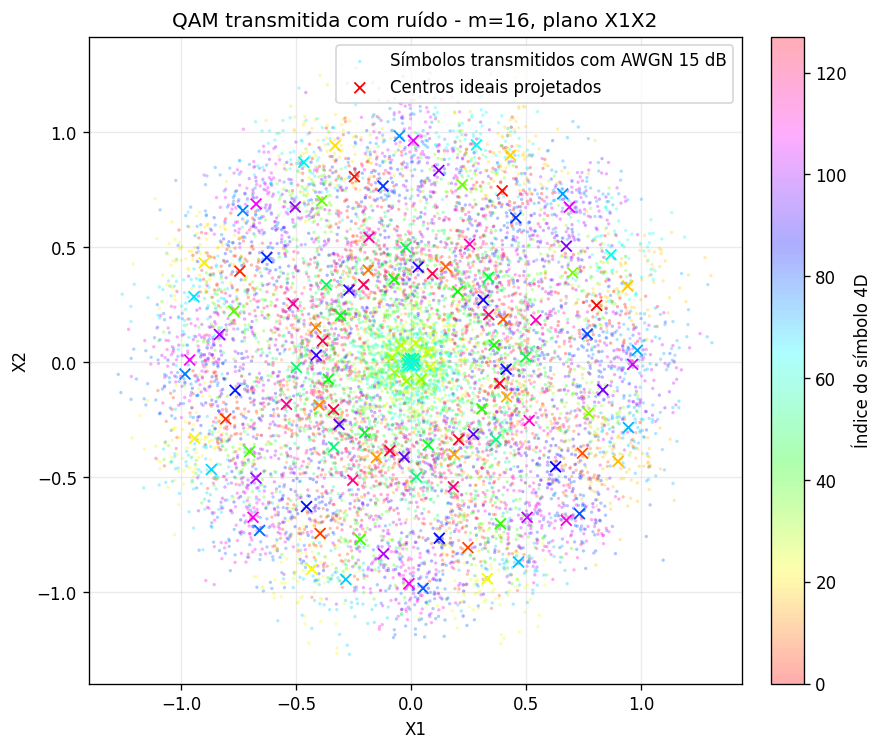

...

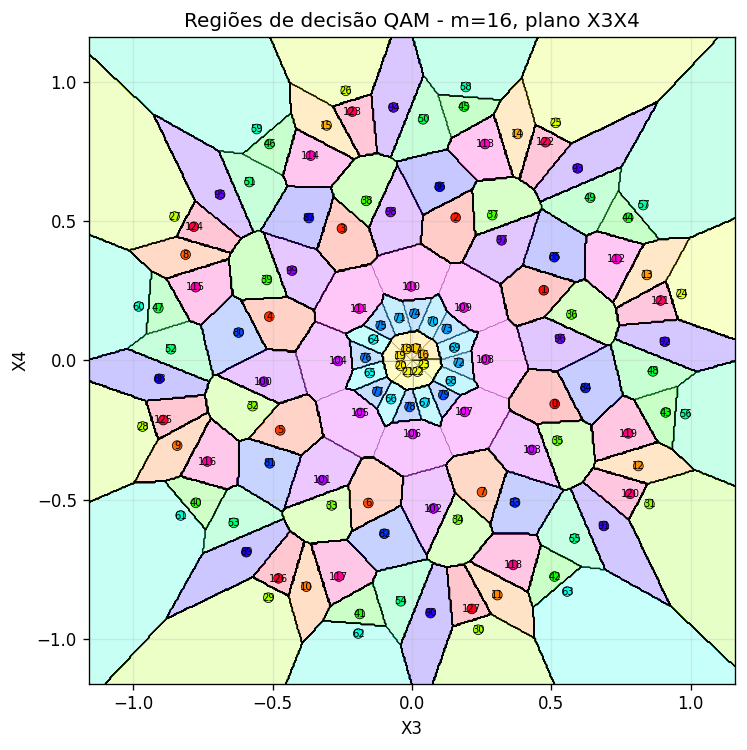

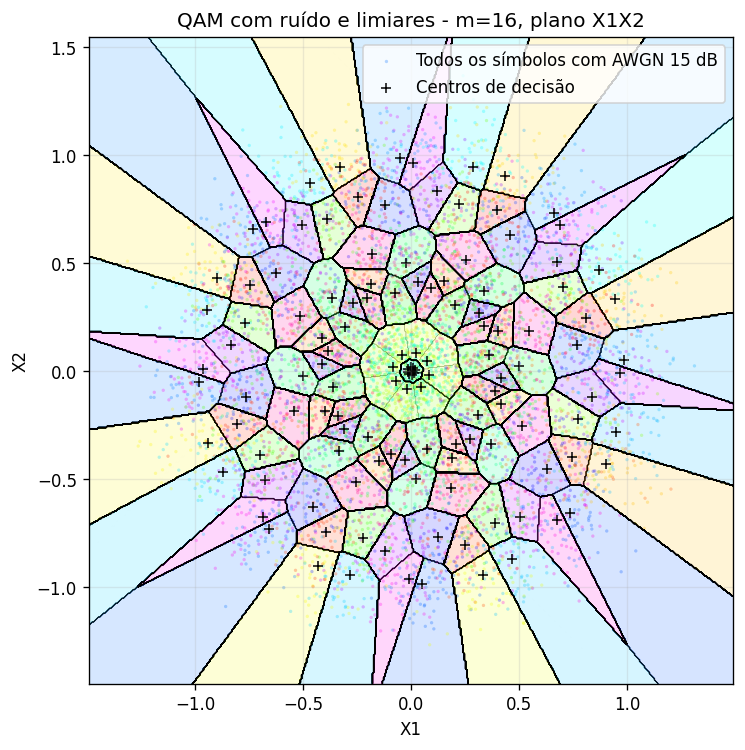

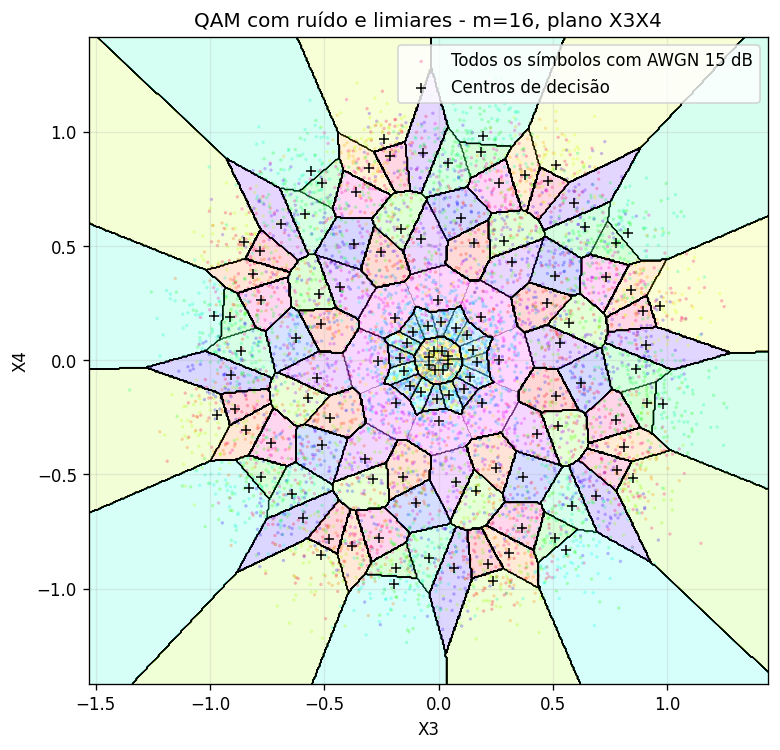

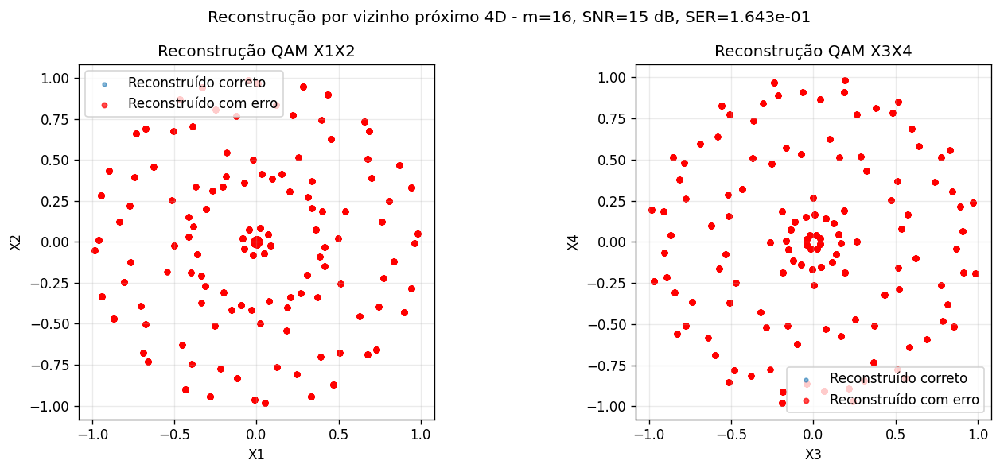

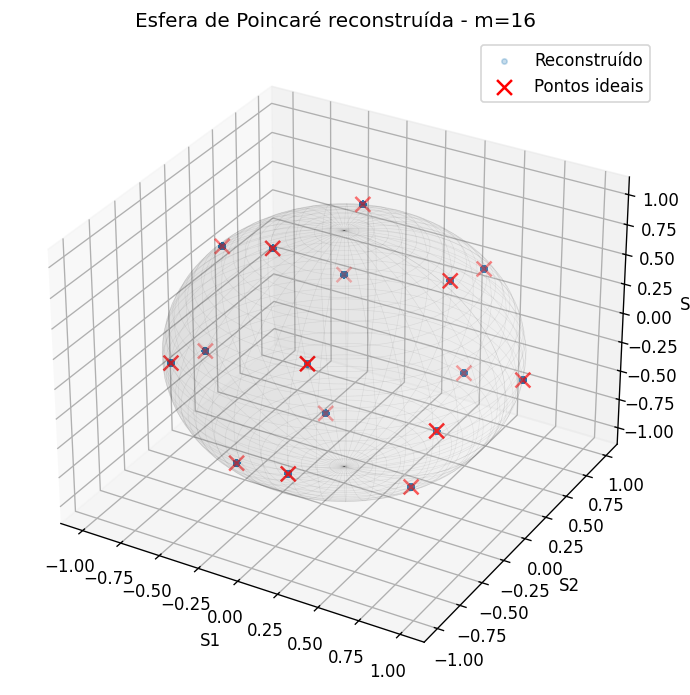

In [ ]:
m_case = 16

diagnose_qam_projection(m_case)

plot_spherical_code_with_noise(m_case, snr_db=SNR_VISUAL_DB)
plot_noisy_hopf_fibers(m_case, snr_db=SNR_VISUAL_DB)

plot_noisy_qam(m_case, axes=(0, 1), snr_db=SNR_VISUAL_DB)
plot_noisy_qam(m_case, axes=(2, 3), snr_db=SNR_VISUAL_DB)

plot_noisy_qam_all_symbols(m_case, axes=(0, 1), snr_db=SNR_VISUAL_DB)
plot_noisy_qam_all_symbols(m_case, axes=(2, 3), snr_db=SNR_VISUAL_DB)

plot_decision_regions(m_case, axes=(0, 1), resolution=520)
plot_decision_regions(m_case, axes=(2, 3), resolution=520)

plot_decision_regions_with_noise(m_case, axes=(0, 1), snr_db=SNR_VISUAL_DB, resolution=520)
plot_decision_regions_with_noise(m_case, axes=(2, 3), snr_db=SNR_VISUAL_DB, resolution=520)

fig_rec_m16, axes_rec_m16, y_true_m16, y_pred_m16, x_rec_m16 = plot_qam_reconstruction(m_case, snr_db=SNR_VISUAL_DB)
plot_reconstructed_sphere(m_case, y_pred_m16)
plt.show()


## CNN e curvas para `m = 16`

O caso `m = 16` possui `16 x 8 = 128` símbolos, portanto a CNN tem 128 classes e o BER natural usa 7 bits por símbolo. Se o treinamento ficar pesado, reduza `n_per_symbol` ou `epochs`.


Época 01/25 | loss=4.56207 | val_acc=0.1544
Época 02/25 | loss=3.02422 | val_acc=0.6629
Época 03/25 | loss=1.74748 | val_acc=0.7699
Época 04/25 | loss=1.19072 | val_acc=0.7887
Época 05/25 | loss=0.93060 | val_acc=0.8087
Época 06/25 | loss=0.79500 | val_acc=0.8103
Época 07/25 | loss=0.71635 | val_acc=0.8133
Época 08/25 | loss=0.67123 | val_acc=0.8204
Época 09/25 | loss=0.63324 | val_acc=0.8176
Época 10/25 | loss=0.61228 | val_acc=0.8234
Época 11/25 | loss=0.59417 | val_acc=0.8194
Época 12/25 | loss=0.58134 | val_acc=0.8214
Época 13/25 | loss=0.57164 | val_acc=0.8195
Época 14/25 | loss=0.56166 | val_acc=0.8249
Época 15/25 | loss=0.55369 | val_acc=0.8234
Época 16/25 | loss=0.54526 | val_acc=0.8273
Época 17/25 | loss=0.54085 | val_acc=0.8234
Época 18/25 | loss=0.53548 | val_acc=0.8194
Época 19/25 | loss=0.52860 | val_acc=0.8234
Época 20/25 | loss=0.52798 | val_acc=0.8250
Época 21/25 | loss=0.52734 | val_acc=0.8281
Época 22/25 | loss=0.52396 | val_acc=0.8250
Época 23/25 | loss=0.51784 | val

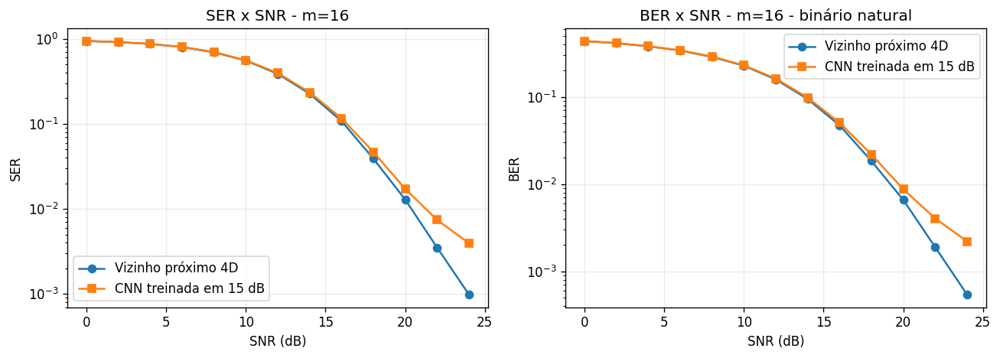

In [ ]:
RUN_CNN_M16 = True

model_m16 = device_m16 = None
if RUN_CNN_M16 and TORCH_AVAILABLE:
    model_m16, history_m16, device_m16 = train_cnn_detector(m=16, snr_db=SNR_VISUAL_DB, n_per_symbol=300, epochs=25)

results_m16 = evaluate_over_snr(m=16, model=model_m16, device=device_m16, n_per_symbol=500)
plot_error_curves(results_m16, m=16)
plt.show()


# Análise estatística das métricas da CNN

Esta seção repete o experimento várias vezes com sementes diferentes e calcula:

- acurácia;
- precisão macro;
- recall macro;
- F1-score macro;
- SER;
- BER.

A tabela é calculada no espaço 4D completo, pois a CNN classifica os símbolos 4D. Os planos `(X1, X2)` e `(X3, X4)` são usados para visualização, mas não devem separar a métrica da CNN.

O resultado final é apresentado como `média ± desvio padrão`. O código também calcula intervalo de confiança de 95% e salva os resultados em CSV.


In [ ]:
# Para a tabela final do trabalho, use N_REPEATS = 30, 50 ou 100.
# Use N_REPEATS = 5 primeiro se quiser testar rapidamente o fluxo.

RUN_REPEATED_METRICS = False

M_VALUES_REPEATED = (4, 8, 16)
SNR_METRICS_DB = 15
N_REPEATS = 20

TRAIN_N_PER_SYMBOL_REPEATED = 300
TEST_N_PER_SYMBOL_REPEATED = 800
EPOCHS_REPEATED = 25
BATCH_SIZE_REPEATED = 256

if RUN_REPEATED_METRICS:
    metric_rows = repeated_metric_analysis(
        m_values=M_VALUES_REPEATED,
        snr_db=SNR_METRICS_DB,
        n_repeats=N_REPEATS,
        train_n_per_symbol=TRAIN_N_PER_SYMBOL_REPEATED,
        test_n_per_symbol=TEST_N_PER_SYMBOL_REPEATED,
        epochs=EPOCHS_REPEATED,
        batch_size=BATCH_SIZE_REPEATED,
        include_ml_baseline=True,
    )
    metric_summary = summarize_metric_rows(metric_rows)
    print_metric_summary(metric_summary)
    save_metric_tables(
        metric_rows,
        metric_summary,
        prefix=f"metricas_repetidas_SNR{SNR_METRICS_DB}dB_N{N_REPEATS}",
    )
else:
    print("Análise estatística não executada. Defina RUN_REPEATED_METRICS = True para gerar a tabela.")


Análise estatística não executada. Defina RUN_REPEATED_METRICS = True para gerar a tabela.


## Observações finais

- A SNR de 15 dB é mantida como cenário gráfico fixo.
- O BER usa binário natural, sem Gray.
- As curvas SER/BER continuam usando vários valores de SNR.
- As regiões de decisão são projeções 2D. A decisão de desempenho é feita no espaço 4D completo.
- Para `m = 8`, a QAM usa a construção angular validada com `theta_vals` e `phi_vals`, não a projeção direta de `ex`, `ey` e `phase_deg`.
- Para `m = 16`, a QAM usa a mesma lógica angular aplicada ao `m = 8`, calculada a partir das coordenadas cartesianas da Tabela 10.
- A análise estatística da CNN deve ser feita com múltiplas execuções independentes e reportada como média ± desvio padrão.
